In [1]:
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# I used Claude to help refactor the anistropy.ipynb notebook to invert for the sigma case

In [3]:
# I used Claude to help refactor this notebook to implement different layers in the simulation - piecewise homogeneity

In [4]:
# numpy casting helper function
def to_numpy(tensor):
    """np.gradient needs a numpy array: pass numpy straight through, otherwise
    detach the torch tensor from the graph and convert."""
    if isinstance(tensor, np.ndarray):
        return tensor
    return tensor.detach().cpu().numpy()

## Collapsed Maxwell Equations

Conductivity-weighted Poisson problem with homogeneous Neumann boundary condition (perfectly insulating boundaries):

$$
\begin{cases}
\nabla \cdot (\sigma(\mathbf{x}) \nabla \phi) = -I & \text{in } \Omega \\[4pt]
\sigma(\mathbf{x}) \dfrac{\partial \phi}{\partial \mathbf{n}} = \sigma(\mathbf{x}) \nabla \phi \cdot \mathbf{n} = 0 & \text{on } \partial\Omega
\end{cases}
$$

We assume conductivity to be a *field* $\sigma(\mathbf{x})$ rather than a single tensor, because the domain contains four tissues.

The current source density $I(x)$ is interpreted as the volume density of current entering or leaving the extracellular medium at position $x \in \Omega$. A
negative CSD corresponds to current leaving the extracellular medium
(due to the fibre transmembrane currents) and is thus conventionally
called a sink. Likewise, current entering the extracellular medium is
called a source (excerpt from the paper below)

**Reference**: <br>
maksymenko2023, <br>
author  = {K. Maksymenko and A. K. Clarke and I. {Mendez Guerra} and S. Deslauriers-Gauthier and D. Farina}, <br>
title   = {A myoelectric digital twin for fast and realistic modelling in deep learning}, <br>
journal = {Nature Communications}, <br>
volume  = {14}, <br>
pages   = {1600}, <br>
year    = {2023}, <br>
doi     = {10.1038/s41467-023-37238-w}

Here $\Omega = [0,L]^3 \subseteq \mathbb{R}^3$ because we are in 3D.

### The conductivity is piecewise homogeneous

In this notebook the tissue conductivity tensor $\sigma$ is piecewise homogeneous and anisotropic: constant within each tissue, discontinuous across the interfaces between them. Four tissues are arranged as concentric shells about the limb axis $(x_c, y_c) = (0.5, 0.5)$, invariant along $z$ — bone core, then muscle, fat, and skin. This is the space-invariant layered limb of Mesin (2013), Fig. 1C, flattened onto a Cartesian box: the interfaces are circles in the transverse plane, but the **outer boundary of the domain stays square**, with the skin shell filling out to the four lateral faces. There is no exterior air region, so the insulating Neumann condition on $\partial\Omega$ *is* the skin–air interface, air conductivity being neglected exactly as Mesin does.

Writing $r(\mathbf{x}) = \lVert (x - x_c,\, y - y_c) \rVert$ for the transverse distance from the axis, the four shells are

1. bone, $0 \le r < R_1$;
2. muscle, $R_1 \le r < R_2$;
3. fat, $R_2 \le r < R_3$;
4. skin, $R_3 \le r$, out to the square boundary.

Only muscle is anisotropic. With the fibres along $z$, the tensor in each shell is diagonal,

$$
\sigma(\mathbf{x}) = \begin{pmatrix} \sigma_T(\mathbf{x}) & 0 & 0 \\ 0 & \sigma_T(\mathbf{x}) & 0 \\ 0 & 0 & \sigma_L(\mathbf{x}) \end{pmatrix},
$$

with $\sigma_T = \sigma_L$ in the three isotropic tissues. The off-diagonals vanish because the fibre axis is aligned with a grid axis; if the fibres ran diagonal to the mesh, $\sigma$ would no longer be diagonal, mixed derivatives would appear, and a 7-point stencil would no longer suffice.

**This needs actual verification (job for later)**
For the muscle shell Mesin (2013), Section 2.2.9 gives $\sigma_T = 0.09$ S/m and $\sigma_L = 0.4$ S/m, and for subcutaneous (fat) tissue $4\times 10^{-2}$ S/m, isotropic. The resulting muscle anisotropy ratio is $R_a = \sigma_L/\sigma_T = 0.4/0.09 \approx 4.44$, consistent with the paper's general statement that conductivity along the fibres is about five times that across them. Bone and skin are placeholders: Mesin draws both but gives bone no value and explicitly declines one for skin.

### The operator no longer collapses

In the previous, homogeneous version of this notebook, $\sigma$ was a constant tensor and could be pulled straight out of the divergence,

$$
\nabla \cdot (\sigma \nabla \phi) = \sigma_T(\partial_{xx} + \partial_{yy})\phi + \sigma_L \partial_{zz}\phi .
$$

That collapse is no longer valid. Expanding the divergence by the product rule for a diagonal $\sigma$,

$$
\nabla \cdot (\sigma \nabla \phi)
= \sum_{d \in \{x,y,z\}} \partial_d\big(\sigma_d\, \partial_d \phi\big)
= \underbrace{\sum_{d} \sigma_d\, \partial_{dd} \phi}_{\text{the old expression}}
\;+\; \underbrace{\sum_{d} (\partial_d \sigma_d)\, \partial_d \phi}_{\text{new, and not zero}} .
$$

Because $\sigma$ is piecewise constant, $\partial_d \sigma_d$ vanishes in the *interior* of every shell but is a Dirac measure supported on the interfaces, where $\sigma$ jumps. The collapsed form is therefore correct **within** a shell and wrong **across** an interface. The divergence form is the one to keep, and it is the one the discretisation must reproduce.

### Interface conditions

The strong form does not hold pointwise on an interface $\Gamma$, so we work with the weak solution $\phi \in H^1(\Omega)$. Take a pillbox straddling $\Gamma$: a small patch $S \subset \Gamma$ thickened by $\pm\varepsilon$ along the normal $\mathbf{n}$. Integrating the PDE over the pillbox and applying the divergence theorem gives

$$
\oint_{\partial(\text{pillbox})} \mathbf{n}\cdot(\sigma\nabla\phi)\, dS = -\int_{\text{pillbox}} I\, dV .
$$

As $\varepsilon \to 0$ the side walls contribute nothing and the volume integral vanishes for bounded $I$, leaving the two flat faces. Writing $[\,f\,]_\Gamma = f^+ - f^-$ for the jump across $\Gamma$, the two conditions are

$$
[\,\phi\,]_\Gamma = 0, \qquad \big[\,\mathbf{n}\cdot(\sigma\nabla\phi)\,\big]_\Gamma = 0 .
$$

The potential is continuous; the *normal current density* is continuous; the normal derivative $\partial\phi/\partial n$ itself is **not** — it jumps by the inverse ratio of the conductivities. So $\phi$ is continuous but has a kink at every interface. This breaks the smoothness assumption behind the Taylor expansion that justifies the second-order central-difference stencil, which is why the stencil is rewritten in flux form below.

### The structural simplification: heterogeneity and anisotropy decouple

Every internal interface is a cylinder generated by translating a curve along $z$, so its outward normal has no $z$ component:

$$
\mathbf{n} = (n_x,\, n_y,\, 0).
$$

Substituting into the flux, the $\sigma_L$ term is multiplied by $n_z = 0$ and drops out:

$$
\mathbf{n}\cdot(\sigma\nabla\phi)
= \sigma_T n_x \partial_x\phi + \sigma_T n_y \partial_y\phi + \sigma_L \cdot 0 \cdot \partial_z\phi
= \sigma_T\, \nabla\phi\cdot\mathbf{n}.
$$

Three consequences follow, and the discretisation exploits all of them:

1. $\sigma_L$ never enters a transmission condition. Longitudinal conductivity is only ever felt *inside* a shell, never across a jump.
2. $\partial_z \phi$ is a tangential derivative on $\Gamma$, hence continuous there — the $z$ direction sees no interface at all.
3. Consequently the discrete $z$-face coefficients never straddle a material jump and can take the plain shell value of $\sigma_L$; only the $x$- and $y$-face coefficients need an interface-aware average, and only ever between two $\sigma_T$ values.

In [5]:
# 3D domain setup

# reproducibility
# inverse problem involves optimisation from an initial guess
torch.manual_seed(42)
np.random.seed(42)

# double precision needed throughout
# float32 causes round-off errors in the gradient when we differentiate for the inverse problem
torch.set_default_dtype(torch.float64)

# 3D domain - [0, L]^3
L = 1.0
N = 65  # number of grid points per axis

# vertex-centred structured grid
t = torch.linspace(0.0, L, N)
h = t[1] - t[0]  # constant grid spacing

X, Y, Z = torch.meshgrid(t, t, t, indexing="ij") # we need this for finite differencing later
x = torch.stack([X, Y, Z], axis=-1)

assert X.shape == Y.shape == Z.shape == (N, N, N)
assert x.shape == (N, N, N, 3)

print(f"Domain [0, {L}]^3 discretised with N = {N} points per axis ({N**3:,} total grid points)")
print(f"Grid spacing h = {h.item():.6f} = L/(N-1) = {L/(N-1):.6f}")
print(f"Coordinate grids X, Y, Z each have shape {tuple(X.shape)}")

# quick grid spacing checks
assert torch.isclose(x[-1, -1, -2][2], torch.tensor(1 - 1/64))
assert torch.isclose(x[-1, -1, -1][2] - x[-1, -1, -2][2], h)

Domain [0, 1.0]^3 discretised with N = 65 points per axis (274,625 total grid points)
Grid spacing h = 0.015625 = L/(N-1) = 0.015625
Coordinate grids X, Y, Z each have shape (65, 65, 65)


In [6]:
# Ground-truth conductivities and the piecewise-homogeneous shell geometry.
#
# Four tissues as concentric shells about the limb axis (X_C, Y_C) = (0.5, 0.5),
# invariant along z (the fibre axis): bone core, then muscle, fat, skin.
# The OUTER boundary of the domain stays square - the skin shell fills out to the
# four lateral faces, so there is no exterior/air region and the insulating Neumann
# condition on the cube boundary IS the skin-air interface.

LAYERED = True        # False -> single homogeneous medium (previous version of this notebook)
SHELL_NORM = "l2"     # 'l2'   -> circular interfaces (staircased on a Cartesian grid)
                      # 'linf' -> square interfaces (axis-parallel, so no staircasing)

X_C, Y_C = 0.5, 0.5   # limb axis, in the transverse (x, y) plane

# interface radii in units of L:  bone [0, R1) | muscle [R1, R2) | fat [R2, R3) | skin [R3, .)
# NOT from Mesin (2013) - the paper gives no limb radii. Our own modelling choice, set so
# that every shell is resolved by several grid cells at N = 65. See the note on skin below.
R1, R2, R3 = 0.12, 0.36, 0.44

# fall back if we set LAYERED = False
# R_a = SIGMA_L / SIGMA_T = 5
# follows the theory outlined in Lucas Mesin 2013 paper
SIGMA_T_TRUE = 1.0 # conductivity along orthogonal direction
SIGMA_L_TRUE = 5.0 # conductivity along longitudinal direction

# per-layer (sigma_T, sigma_L) in S/m. Only muscle is anisotropic; the other three
# tissues are isotropic, so sigma_T = sigma_L there.
#
#   muscle : sigma_T = 0.09, sigma_L = 0.4 S/m.  Mesin (2013), Sec. 2.2.9 and the Fig. 1
#            annotation; attributed there to Gielen, Wallinga-de Jonge & Boon,
#            Med. Biol. Eng. Comput. 22 (1984) 569-577.
#   fat    : 4e-2 S/m, isotropic ("subcutaneous tissue"). Mesin (2013), Sec. 2.2.9;
#            attributed there to Gabriel, Lau & Gabriel, Phys. Med. Biol. 41 (1996) 2251-2269.
#   bone   : PLACEHOLDER. Mesin draws bone in Fig. 1 but gives it no conductivity.
#   skin   : PLACEHOLDER. Mesin explicitly declines a value ("conductivity depending on
#            many factors, such as sweat"). Real skin spans orders of magnitude.
LAYER_NAMES  = ["bone", "muscle", "fat", "skin"]
SIGMA_LAYERS = {
    "bone":   (0.02, 0.02),   # PLACEHOLDER - needs a cited value
    "muscle": (0.09, 0.40),   # Mesin (2013)
    "fat":    (0.04, 0.04),   # Mesin (2013)
    "skin":   (0.05, 0.05),   # PLACEHOLDER - needs a cited value
}

assert 0.0 < R1 < R2 < R3 < 0.5, "radii must be ordered, and skin must reach the lateral faces"
assert list(SIGMA_LAYERS) == LAYER_NAMES

In [7]:
# crucial helpers

def shell_radius(n, norm=None):
    """
    Transverse distance field r(x, y) on the n x n vertex-centred slice of [0, L]^2,
    measured from the limb axis (X_C, Y_C). Shape (n, n); no z dependence by construction.

    norm='l2'   -> r = sqrt(dx^2 + dy^2), circular interfaces
    norm='linf' -> r = max(|dx|, |dy|),  square interfaces
    """
    norm = SHELL_NORM if norm is None else norm
    t_n = torch.linspace(0.0, L, n)
    X_n, Y_n = torch.meshgrid(t_n, t_n, indexing="ij")
    dx, dy = X_n - X_C, Y_n - Y_C
    if norm == "l2":
        return torch.sqrt(dx ** 2 + dy ** 2)
    if norm == "linf":
        return torch.maximum(dx.abs(), dy.abs())
    raise ValueError(f"SHELL_NORM must be 'l2' or 'linf', got {norm!r}")


def build_layer_index(n, norm=None):
    """
    Layer label field, shape (n, n, n), entries 0..3 indexing LAYER_NAMES.

    Tie-break: the shells are half-open intervals closed on the LEFT, so a node lying
    exactly on an interface (r == R_k to machine precision) is assigned to the OUTER
    layer. The successive torch.where calls sweep outwards, which realises exactly that.
    The rule matters only for exact hits; it is stated so the labelling is deterministic
    and independent of grid size.
    """
    r   = shell_radius(n, norm)
    idx = torch.zeros(n, n, dtype=torch.long)                 # 0 = bone
    for k, R in enumerate((R1, R2, R3), start=1):
        idx = torch.where(r >= R, torch.full_like(idx, k), idx)
    return idx.unsqueeze(-1).expand(n, n, n).contiguous()     # broadcast along z


def sigma_vectors_from_dict():
    """Length-4 (sigma_T, sigma_L) vectors from SIGMA_LAYERS, ordered as LAYER_NAMES.
    torch.stack, not torch.tensor, so this path also works when the entries are
    differentiable tensors (the inverse problem passes its iterates through here)."""
    sT = torch.stack([torch.as_tensor(SIGMA_LAYERS[nm][0]) for nm in LAYER_NAMES])
    sL = torch.stack([torch.as_tensor(SIGMA_LAYERS[nm][1]) for nm in LAYER_NAMES])
    return sT, sL


def build_sigma_fields(n, layered=None, norm=None, sT_vec=None, sL_vec=None):
    """(sigma_T, sigma_L) as two (n, n, n) fields.

    sT_vec, sL_vec omitted -> read the ground-truth values from SIGMA_LAYERS (data gen).
    sT_vec, sL_vec given    -> use those length-4 vectors instead; the inversion passes
                               its current conductivity iterates this way, and because the
                               gather sT_vec[idx] is differentiable, gradients reach them.
    """
    layered = LAYERED if layered is None else layered
    if not layered:
        return (torch.full((n, n, n), SIGMA_T_TRUE), torch.full((n, n, n), SIGMA_L_TRUE))
    if sT_vec is None or sL_vec is None:
        sT_vec, sL_vec = sigma_vectors_from_dict()
    idx = build_layer_index(n, norm)
    return sT_vec[idx], sL_vec[idx]

### Visualising the shell geometry

Two figures verify the geometry before it is used. The first is static: a transverse tissue map and the radial conductivity profile read straight off the assembled $\sigma$ fields. The second animates the $x$–$y$ cross-section along $z$.

The animation is the visual proof of $z$-invariance: **the rings do not move as the slider advances**. Only the source $I$ changes from frame to frame. This is the geometric assumption the discretisation exploits — every internal interface is a cylinder generated by translation along $z$, so its normal has no $z$ component, and consequently $\sigma_L$ never enters a transmission condition and no $z$-face coefficient ever straddles a material jump.

Both panels carry two representations of the same interfaces, and the gap between them is the point:

1. the **blocky colour boundary**, which is what the grid actually resolves — each node is assigned wholesale to one tissue;
2. the **smooth black curves**, which are the exact circles $r = R_1, R_2, R_3$.

The mismatch between them is the staircasing error. It is a genuine geometric modelling error, not a solver defect, and it is why we should expect only first-order accuracy on the circular geometry even though the scheme is second order on a plane interface. Setting `SHELL_NORM = 'linf'` replaces the circles with axis-parallel squares, removes the staircasing entirely, and gives a controlled comparison: the difference in recovered conductivities between the two norms is a direct estimate of how much the geometric error costs.

interface radii recovered from the field: [0.125  0.375  0.4531]   intended: (0.12, 0.36, 0.44)   (tolerance h = 0.01562)


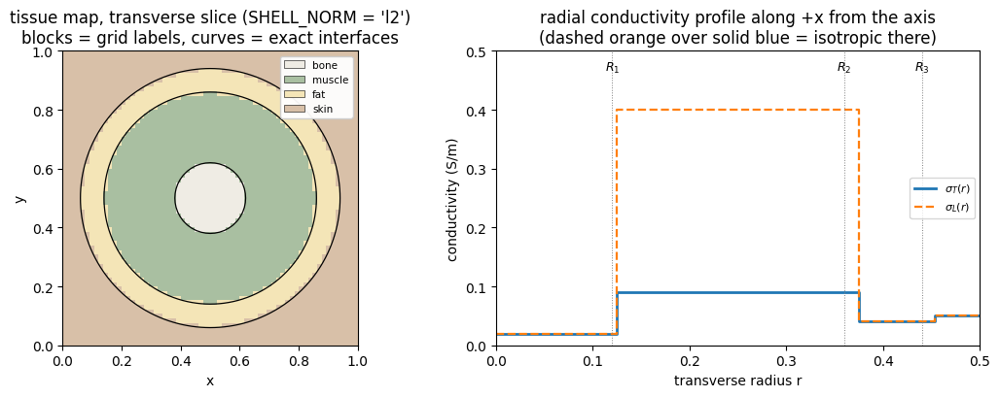

In [8]:
# tissue map and radial conductivity profile, read off the assembled sigma fields
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

TISSUE_COLOURS = ["#efece4", "#a9bfa1", "#f4e5b7", "#d8c0a8"]   # bone, muscle, fat, skin
tissue_cmap = ListedColormap(TISSUE_COLOURS)
tissue_norm = BoundaryNorm(np.arange(-0.5, len(LAYER_NAMES)), tissue_cmap.N)

layer_np = to_numpy(build_layer_index(N))
r_np     = to_numpy(shell_radius(N))
sigma_T_field, sigma_L_field = build_sigma_fields(N)
sT_np    = to_numpy(sigma_T_field)
sL_np    = to_numpy(sigma_L_field)
t_np     = to_numpy(t)

# --- verification -----------------------------------------------------------------
# z-invariance: compare slice 0 against a randomly chosen slice
k_probe = int(torch.randint(0, N, (1,)))
assert (sT_np[:, :, 0] == sT_np[:, :, k_probe]).all(), "sigma_T is not z-invariant"
assert (sL_np[:, :, 0] == sL_np[:, :, k_probe]).all(), "sigma_L is not z-invariant"

# the outermost (skin) shell must reach all four lateral faces
skin = LAYER_NAMES.index("skin")
for face in (layer_np[0], layer_np[-1], layer_np[:, 0], layer_np[:, -1]):
    assert (face == skin).all(), "skin shell does not reach a lateral face"

# recover the interface radii from the field itself, along the +x ray from the axis,
# and check they land within one grid spacing of the intended values
i_c = int(round(X_C * (N - 1)))
assert abs(t_np[i_c] - X_C) < 1e-12, "limb axis does not sit on a grid node"
r_ray  = t_np[i_c:] - X_C
sT_ray = sT_np[i_c:, i_c, 0]
sL_ray = sL_np[i_c:, i_c, 0]
jumps  = r_ray[1:][sT_ray[1:] != sT_ray[:-1]]
print(f"interface radii recovered from the field: {np.round(jumps, 4)}   "
      f"intended: {(R1, R2, R3)}   (tolerance h = {h.item():.5f})")
for R in (R1, R2, R3):
    assert np.abs(jumps - R).min() <= h.item(), f"interface {R} not resolved on the grid"

# --- figure -----------------------------------------------------------------------
fig, (ax_map, ax_prof) = plt.subplots(1, 2, figsize=(11, 4.2))

ax_map.imshow(layer_np[:, :, 0].T, origin="lower", extent=[0, L, 0, L],
              cmap=tissue_cmap, norm=tissue_norm, interpolation="nearest")
ax_map.contour(t_np, t_np, r_np.T, levels=[R1, R2, R3], colors="k", linewidths=0.9)
ax_map.set_xlabel("x"); ax_map.set_ylabel("y")
ax_map.set_title(f"tissue map, transverse slice (SHELL_NORM = {SHELL_NORM!r})\n"
                 "blocks = grid labels, curves = exact interfaces")
ax_map.legend(handles=[Patch(facecolor=c, edgecolor="k", linewidth=0.4, label=nm)
                       for nm, c in zip(LAYER_NAMES, TISSUE_COLOURS)],
              loc="upper right", fontsize=7.5, framealpha=0.95)

ax_prof.step(r_ray, sT_ray, where="post", color="tab:blue",   lw=2.0, label=r"$\sigma_T(r)$")
ax_prof.step(r_ray, sL_ray, where="post", color="tab:orange", lw=1.6, ls="--", label=r"$\sigma_L(r)$")
top = 1.25 * max(sT_ray.max(), sL_ray.max())
ax_prof.set_ylim(0, top); ax_prof.set_xlim(0, r_ray.max())
for R, nm in zip((R1, R2, R3), ("$R_1$", "$R_2$", "$R_3$")):
    ax_prof.axvline(R, color="grey", lw=0.7, ls=":")
    ax_prof.text(R, top * 0.97, nm, ha="center", va="top", fontsize=9)
ax_prof.set_xlabel("transverse radius r"); ax_prof.set_ylabel("conductivity (S/m)")
ax_prof.set_title("radial conductivity profile along +x from the axis\n"
                  "(dashed orange over solid blue = isotropic there)")
ax_prof.legend(fontsize=8, loc="center right")
fig.tight_layout()
plt.show();

Point about notation, $\phi_{i,j,k}$ is shorthand for $\phi(x_{i,j,k})$, where $(i, j, k)$ are the spatial coordinates within the 3D boundary $\Omega \subseteq \mathbb{R^3}$.

### From the collapsed stencil to the flux form

The previous version of this notebook discretised $\nabla\cdot(\sigma\nabla\phi)$ by first collapsing it to $\sum_d \sigma_d\,\partial_{dd}\phi$ and then applying a central second difference on each axis. As the previous cell showed, that collapse is invalid once $\sigma$ jumps. We therefore discretise the divergence form directly, in two steps, keeping the flux intact.

**Step 1 — outer derivative on the half grid.** The quantity inside the divergence is the current density component $J_d = -\sigma_d\,\partial_d\phi$. Evaluate it at the two faces of the cell surrounding node $i$, at $x_{i\pm 1/2}$, and difference across the cell:

$$
\partial_x\big(\sigma_x\,\partial_x \phi\big)\Big|_{i,j,k}
\;\approx\;
\frac{\big(\sigma_x\,\partial_x\phi\big)_{i+\frac12,j,k} - \big(\sigma_x\,\partial_x\phi\big)_{i-\frac12,j,k}}{h}.
$$

**Step 2 — inner derivative across each half cell.** Each face sits midway between two nodes, so a central difference there is a plain nodal difference:

$$
\big(\partial_x\phi\big)_{i+\frac12,j,k} \approx \frac{\phi_{i+1,j,k} - \phi_{i,j,k}}{h},
\qquad
\big(\partial_x\phi\big)_{i-\frac12,j,k} \approx \frac{\phi_{i,j,k} - \phi_{i-1,j,k}}{h}.
$$

**Combining.** Substituting Step 2 into Step 1 and doing the same on the other two axes gives the scheme we implement:

$$
\big[\nabla\cdot(\sigma\nabla\phi)\big]_{i,j,k}
\;\approx\;
\frac{1}{h^2}\sum_{d \in \{x,y,z\}}
\Big[\, \sigma^{d}_{+\frac12}\big(\phi_{+e_d} - \phi\big) \;-\; \sigma^{d}_{-\frac12}\big(\phi - \phi_{-e_d}\big) \Big],
$$

where $e_d$ is the unit step along axis $d$ and $\sigma^{d}_{\pm 1/2}$ is the conductivity assigned to the corresponding face. Note that each difference still spans a full grid spacing $h$; only the *coefficients* live on the half grid. Two properties follow immediately and are worth stating because both are used later:

1. Every term is a difference of $\phi$ values, so a constant field is annihilated for **any** choice of positive face coefficients. The gauge freedom $A\mathbf{1} = 0$ survives heterogeneity untouched.
2. The coefficient on the face between two nodes is shared between their two rows with opposite sign, so the flux leaving one control volume is exactly the flux entering its neighbour. Current is conserved discretely, by construction, not merely to truncation order.

**Recovering the old stencil.** Inside a single shell all face coefficients on an axis equal that shell's conductivity, $\sigma^d_{\pm 1/2} = \sigma_d$, and the bracket telescopes:

$$
\frac{1}{h^2}\sum_d \sigma_d\Big[\big(\phi_{+e_d}-\phi\big)-\big(\phi-\phi_{-e_d}\big)\Big]
= \frac{1}{h^2}\sum_d \sigma_d\big(\phi_{+e_d}+\phi_{-e_d}-2\phi\big),
$$

which is exactly the weighted 7-point stencil used before. The flux form is a strict generalisation: it reduces to the previous kernel wherever the medium is homogeneous, and that identity is the first regression test in the validation ladder.

### Why the face conductivity is a harmonic mean

The face coefficient is not free. Consider two adjacent nodes $A$ at $x_i$ and $B$ at $x_{i+1}$, in different tissues, with the material interface at the face midpoint $x_{i+1/2}$ between them. In steady state with no source in between, the transmission condition of the previous cell says the normal current density $J$ is the **same** on both sides of the interface. Ohm's law $J = -\sigma\,\mathrm{d}\phi/\mathrm{d}x$ then gives the potential drop over each half cell separately:

$$
\Delta\phi_A = J\,\frac{h/2}{\sigma_A},
\qquad
\Delta\phi_B = J\,\frac{h/2}{\sigma_B},
$$

so the total nodal drop is

$$
\phi_A - \phi_B = \Delta\phi_A + \Delta\phi_B = J\,\frac{h}{2}\left(\frac{1}{\sigma_A} + \frac{1}{\sigma_B}\right).
$$

We want the discrete face flux $J = \sigma_{i+\frac12}\,(\phi_A - \phi_B)/h$ to reproduce this exactly. Substituting the line above and cancelling $(\phi_A - \phi_B)$ and $h$:

$$
1 = \frac{\sigma_{i+\frac12}}{2}\left(\frac{1}{\sigma_A} + \frac{1}{\sigma_B}\right)
\qquad\Longrightarrow\qquad
\sigma_{i+\frac12} = \frac{2}{\dfrac{1}{\sigma_A} + \dfrac{1}{\sigma_B}} = \frac{2\,\sigma_A\,\sigma_B}{\sigma_A + \sigma_B}.
$$

This is the harmonic mean, and the reason is physical rather than numerical: the two half cells are resistors **in series**, and series resistances add, so it is the resistivities $1/\sigma$ that average arithmetically, not the conductivities. An arithmetic mean $\tfrac12(\sigma_A+\sigma_B)$ answers a different question — two resistors in parallel — and is dominated by the *better* conductor, whereas a series path is correctly limited by the *worse* one. In the limit $\sigma_B \to 0$ the harmonic mean tends to $0$, as an insulating layer should, while the arithmetic mean tends to $\sigma_A/2$, which is finite and wrong.

**Only the transverse faces need this.** By the decoupling established in the previous cell, every interface is parallel to $z$, so $\sigma_L$ is constant along every $z$-edge of the grid and no $z$-face ever straddles a material jump. Its harmonic mean is therefore the shell's own $\sigma_L$, and only the $x$- and $y$-face coefficients require averaging, always between two $\sigma_T$ values.

### Accuracy, and where it is lost

The scheme is second order for smooth $\sigma$, and for a **plane** interface lying exactly on a face midpoint it is better than that: it reproduces the piecewise-linear solution exactly, because every discrete face flux then equals the true constant flux. That is the strongest available certification of the operator, and it is the gate the planar test in the validation ladder checks.

Two things degrade it, and they should not be confused with a defect in the scheme:

1. **Interface placement.** The derivation above assumed the jump sits at a face midpoint. Where it falls elsewhere within a cell, the node-sampled $\sigma$ misplaces the interface by up to $h/2$ and the accuracy drops to first order.
2. **Staircasing.** A circular interface cannot be aligned to a Cartesian grid at all, so case 1 applies almost everywhere along it and first order is the best we should expect. Setting `SHELL_NORM = 'linf'` removes this and restores the plane-interface behaviour.

We need to use reflect padding like the above cell outlines because it obeys the physics of the homogeneous Neumann boundary condition (insulating boundary). Let's consider the low face of one axis (node index $0$ i.e. $\phi[0]$, where the outward normal points in the $-x$ direction). To approximate the normal derivative at the boundary node (index 0), we use a 2nd order central difference scheme centred at $\phi[0]$, which requires a ghost node at index $-1$ ($\phi[-1]$):

$\left.\dfrac{\partial \phi(x)}{\partial x}\right|_{i=0} \approx \dfrac{\phi(x_{1,j,k}) - \phi(x_{-1,j,k})}{2h}$

Now we impose the homogeneous Neumann boundary, which is the statement that no current leaves the domain, $\mathbf{n}\cdot(\sigma\nabla\phi) = 0$. Because $\sigma$ is positive definite and every face of the cube has its outward normal along a grid axis, exactly one diagonal component of $\sigma$ multiplies the normal derivative and can be divided out, so the flux condition reduces to $\partial\phi/\partial\mathbf{n} = 0$. (This step is specific to an axis-aligned boundary; on a curved or oblique boundary the two conditions would not be interchangeable.) Setting the expression above to $0$:

$\dfrac{\phi(x_{1,j,k}) - \phi(x_{-1,j,k})}{2h} = 0 \implies \phi(x_{1,j,k}) = \phi(x_{-1,j,k})$.

This yields our ghost node value of $\phi(x_{-1,j,k}) = \phi(x_{1,j,k})$, which we implement above. We follow the same method on the high face $\phi(x_{N,j,k}) = \phi(x_{N-2,j,k})$

And we set up normal derivatives similarly at the remaining $4$ faces of our domain (i.e. we do it at both the boundary nodes for each spatial direction $i, j, k$ to give $6$ faces in total).

Now that the conductivity is a field rather than a scalar baked into the kernel weights, there are two things to mirror at each face, not one. The ghost *node* takes the mirrored potential $\phi_{-1} = \phi_1$ as above, and the ghost *face coefficient* takes the mirrored conductivity of the outermost internal face, $\sigma_{-1/2} = \sigma_{+1/2}$. Mirroring both is what keeps the boundary treatment exact: assembling the operator this way agrees to machine precision with a direct finite-volume assembly in which the outward faces are given zero conductivity and each row is divided by its control volume.

It is worth seeing what this does to the boundary row, because the rest of the notebook depends on it. Substituting $\phi_{-1} = \phi_1$ and $\sigma_{-1/2} = \sigma_{+1/2}$ into the flux form, the two half-cell terms at node $0$ reinforce rather than cancel:

$$
\frac{1}{h^2}\Big[\sigma_{+\frac12}\big(\phi_{1}-\phi_{0}\big) - \sigma_{-\frac12}\big(\phi_{0}-\phi_{-1}\big)\Big]
= \frac{2\,\sigma_{+\frac12}}{h^{2}}\big(\phi_{1}-\phi_{0}\big).
$$

The factor of $2$ is not an artefact. A boundary node owns only half a control volume, so its flux balance involves half the volume but a full interior face; dividing through by that half volume produces the $2$. Interior rows carry no such factor, so the rows of $A$ are scaled by the reciprocal of their control volumes, which are exactly the trapezoidal quadrature weights. This is the origin of the asymmetry of $A$ and of the fact — derived in the cells below and verified numerically later — that its right null space is spanned by constants while its left null space is spanned by those trapezoidal weights.

### How the operator is formed in code

The scheme is assembled from two objects: a set of **fixed-weight difference kernels**, which never change, and a set of **face-conductivity fields**, which carry all the physics.

`neighbour_diff_kernels()` returns six $3\times3\times3$ kernels stacked as a single `(6, 1, 3, 3, 3)` weight tensor, in the order $+x, -x, +y, -y, +z, -z$. Each kernel has exactly two non-zero entries: $+1$ at the neighbour and $-1$ at the centre. Writing the kernel index as $[a,b,c]$ with the centre at $[1,1,1]$ and axes $0=x$, $1=y$, $2=z$ from `meshgrid(indexing="ij")`, the six are

$$
\begin{aligned}
k_{+x}[2,1,1] &= +1, & k_{+x}[1,1,1] &= -1, \\
k_{-x}[0,1,1] &= +1, & k_{-x}[1,1,1] &= -1, \\
k_{+y}[1,2,1] &= +1, & k_{+y}[1,1,1] &= -1, \\
k_{-y}[1,0,1] &= +1, & k_{-y}[1,1,1] &= -1, \\
k_{+z}[1,1,2] &= +1, & k_{+z}[1,1,1] &= -1, \\
k_{-z}[1,1,0] &= +1, & k_{-z}[1,1,1] &= -1,
\end{aligned}
$$

with the remaining 25 entries of each kernel zero. A single `conv3d` of the reflect-padded potential against this stack returns all six neighbour differences $\phi_{\pm e_d} - \phi$ at once, as a `(6, n, n, n)` tensor. These kernels contain no conductivity and no $h$: they are pure geometry and are built once.

`face_conductivities(sigma_T, sigma_L)` returns a matching `(6, n, n, n)` tensor giving the harmonic-mean conductivity on each of the six faces of every node's control volume, in the same order. Along each axis there are $n-1$ internal faces, so the array is one short of the node count; the missing entry at each end is filled by mirroring the outermost internal face, which is the conductivity half of the reflect boundary treatment derived above.

The operator is then the elementwise product of these two, summed over the six faces:

$$
\big[\nabla\cdot(\sigma\nabla\phi)\big]_{i,j,k} \approx \frac{1}{h^2}\sum_{f=1}^{6}\; \sigma^{(f)}_{i,j,k}\,\big(\phi_{\text{nb}(f)} - \phi\big)_{i,j,k},
$$

which is one line of code. The contrast with the previous version is worth stating plainly. Before, the conductivity was baked into the seven weights of a single kernel, so a homogeneous medium was structurally assumed; the operator could only ever represent constant $\sigma$. Now the kernel weights are $\pm 1$ and constant, and the conductivity has moved out of the kernel and into a coefficient field multiplied elementwise. Heterogeneity costs one extra tensor multiply, and the discretisation is still nothing but a fixed convolution — the Neural Physics framing is unchanged, and gradients with respect to the conductivities still reach the solver by ordinary backpropagation.

The diagonal of the assembled operator falls straight out of the same face fields,

$$
D_{i,j,k} = -\frac{1}{h^2}\sum_{f=1}^{6}\sigma^{(f)}_{i,j,k},
$$

since each neighbour difference contributes $-\sigma^{(f)}$ to the centre. `operator_diagonal` returns it, so the Jacobi smoother and the operator can never disagree about what $\sigma$ is.

In [9]:
# the boundary conditions goes on the sides of the kernel
# Computers and Fluids Paper 2026
# Neural physics: Using AI libraries to develop physics-based solvers for incompressible computational fluid dynamics
# Boyang Chen a, Claire E. Heaney b, Christopher C. Pain

In [10]:
def neighbour_diff_kernels():
    """
    Six fixed-weight 3x3x3 kernels, each computing one neighbour difference
    phi_nb - phi_self. Order: +x, -x, +y, -y, +z, -z.

    These carry no conductivity and no grid spacing - pure geometry, built once.
    """
    offsets = [(1, 0, 0), (-1, 0, 0), (0, 1, 0), (0, -1, 0), (0, 0, 1), (0, 0, -1)]
    k = torch.zeros(6, 1, 3, 3, 3)
    for m, (a, b, c) in enumerate(offsets):
        k[m, 0, 1 + a, 1 + b, 1 + c] = 1.0    # neighbour
        k[m, 0, 1, 1, 1]             = -1.0   # centre
    return k

DIFF_KERNELS = neighbour_diff_kernels()
print(f"DIFF_KERNELS is a torch tensor with shape {DIFF_KERNELS.shape}, this is what neighbour_diff_kernels returns")


def face_conductivities(sigma_T, sigma_L):
    """
    Harmonic-mean conductivity on each of the six faces of every node's control
    volume. Returns (6, n, n, n) in the DIFF_KERNELS order (+x, -x, +y, -y, +z, -z).

    Along each axis there are n-1 internal faces; the entry missing at each end is
    filled by mirroring the outermost internal face, which is the conductivity half
    of the reflect boundary treatment.

    The harmonic mean is used on all three axes. On z it is an identity, because
    sigma_L is z-invariant so adjacent z-nodes always agree and harm(a, a) = a - so
    one code path serves all six faces rather than special-casing the fibre axis.
    """
    harm = lambda a, b: 2.0 * a * b / (a + b)
    cx = harm(sigma_T[:-1, :, :], sigma_T[1:, :, :])   # (n-1, n, n)
    cy = harm(sigma_T[:, :-1, :], sigma_T[:, 1:, :])
    cz = harm(sigma_L[:, :, :-1], sigma_L[:, :, 1:])
    return torch.stack([
        torch.cat([cx, cx[-1:, :, :]], dim=0),   # +x   (mirrored at i = n-1)
        torch.cat([cx[:1, :, :], cx], dim=0),    # -x   (mirrored at i = 0)
        torch.cat([cy, cy[:, -1:, :]], dim=1),   # +y
        torch.cat([cy[:, :1, :], cy], dim=1),    # -y
        torch.cat([cz, cz[:, :, -1:]], dim=2),   # +z
        torch.cat([cz[:, :, :1], cz], dim=2),    # -z
    ])

DIFF_KERNELS is a torch tensor with shape torch.Size([6, 1, 3, 3, 3]), this is what neighbour_diff_kernels returns


In [11]:
def laplacian_3D(phi, h, faces):
    """
    3D operator div(sigma . grad phi) in flux form, for an arbitrary positive
    conductivity field.

    One fixed-weight conv3d produces the six neighbour differences; the six face
    conductivities enter as an elementwise multiply. Reflect padding sets the ghost
    nodes on all six faces (phi[-1] = phi[1], phi[N] = phi[N-2] in each axis).
    """
    n = phi.shape[0]
    assert phi.shape == (n, n, n)
    assert faces.shape == (6, n, n, n), "face field does not match the grid"
    phi_pad = F.pad(phi.view(1, 1, n, n, n), (1,) * 6, mode="reflect")
    diffs   = F.conv3d(phi_pad, DIFF_KERNELS).view(6, n, n, n)
    return (faces * diffs).sum(dim=0) / h ** 2

# mode="reflect" the padded values are copies of existing interior values of phi, mirrored across each face
# take a single axis with values phi[0], phi[1], phi[2],..., phi[N-2], phi[N-1]
# after reflect padding by 1 on each side, the row becomes
# phi[1], phi[0], phi[1], phi[2],..., phi[N-2], phi[N-1], phi[N-2]
# ↑ghost--------------------------------------------------↑ghost
# i.e phi[-1] = phi[1], phi[N] = phi[N-2]

In [12]:
# Regression test: on a homogeneous medium the flux operator must reproduce the
# previous 7-point kernel exactly. This is the gate that certifies the rewrite is a
# strict generalisation and not a change of model.

def _old_kernel_operator(phi, h, sigma_T, sigma_L):
    """The operator this notebook used before the flux rewrite, kept only for this test."""
    n = phi.shape[0]
    k = torch.zeros(3, 3, 3)
    k[1, 1, 1] = -2.0 * (2.0 * sigma_T + sigma_L)
    k[0, 1, 1] = k[2, 1, 1] = sigma_T
    k[1, 0, 1] = k[1, 2, 1] = sigma_T
    k[1, 1, 0] = k[1, 1, 2] = sigma_L
    k = (k / h ** 2).view(1, 1, 3, 3, 3)
    p = F.pad(phi.view(1, 1, n, n, n), (1,) * 6, mode="reflect")
    return F.conv3d(p, k).view(n, n, n)

for n in (9, 17, 33):
    h_n = L / (n - 1)
    phi_test = torch.randn(n, n, n)
    for (sT, sL) in [(SIGMA_T_TRUE, SIGMA_L_TRUE), (1.0, 1.0), (0.09, 0.40)]:
        faces = face_conductivities(torch.full((n, n, n), sT), torch.full((n, n, n), sL))
        new = laplacian_3D(phi_test, h_n, faces)
        old = _old_kernel_operator(phi_test, h_n, sT, sL)
        rel = ((new - old).abs().max() / old.abs().max()).item()
        assert rel < 1e-12, f"flux operator disagrees with the old kernel at n={n}, sigma=({sT},{sL})"
    print(f"  n = {n:3d}: flux operator reproduces the old 7-point kernel, "
          f"max relative difference {rel:.1e}")

# constants must be annihilated for ANY positive conductivity field, layered or not
for lay in (True, False):
    faces = face_conductivities(*build_sigma_fields(N, layered=lay))
    resid = laplacian_3D(torch.ones(N, N, N), h, faces).abs().max().item()
    print(f"  LAYERED = {lay}: ||A 1||_inf = {resid:.2e}")
    assert resid < 1e-9, "constants must lie in the right null space"

  n =   9: flux operator reproduces the old 7-point kernel, max relative difference 2.1e-16
  n =  17: flux operator reproduces the old 7-point kernel, max relative difference 1.7e-16
  n =  33: flux operator reproduces the old 7-point kernel, max relative difference 3.1e-16
  LAYERED = True: ||A 1||_inf = 0.00e+00
  LAYERED = False: ||A 1||_inf = 0.00e+00


In [13]:
print(f"faces is a torch tensor with shape {faces.shape}, this is what face conductivities returns")

faces is a torch tensor with shape torch.Size([6, 65, 65, 65]), this is what face conductivities returns


Our homogeneous Neumann boundary condition yields yet another result we need to account for. Let us integrate the governing PDE over our domain $\Omega$,

$$
\begin{aligned}
\int_\Omega -I\, dV &= \int_\Omega \nabla \cdot (\sigma \nabla\phi)\, dV && \text{by our collapsed maxwell equation} \\[2mm]
&= \oint_{\partial\Omega} \mathbf{n} \cdot (\sigma \nabla\phi)\, dS && \text{by the Divergence Theorem} \\[2mm]
&= 0 && \text{by our boundary condition} \\[2mm]
\implies \int_\Omega I\, dV &= 0\,.
\end{aligned}
$$

https://en.wikipedia.org/wiki/Divergence_theorem

This means our current source distribution has zero-mean.

The skin-air interface is the insulating boundary - we ignore the connductivity of air (as per the Lucas Mesin 2013 paper referenced in the project plan literature review).

Since there is net zero flux through $\partial\Omega$ (no current density can escape through the boundary), then intuitively the total current density injected must be the same as the amount that's absorbed i.e. the sinks and sources cancel each other out. And we can also see the algebraic justification for this above.

However, the above algebra highlights the solvability condition in the continuos case, but we are working in the discrete scenario. Therefore, to motivate our implementation of this requirement, we need to introduce some background linear algebra.

The orthogonal complement of a subspace $W$ is defined as

$$
W^{\perp} = \{\, v : v \cdot w = 0 \text{ for all } w \in W \,\},
$$

i.e. the set of all vectors which are orthogonal to every vector in $W$.

A matrix $A \in \mathbb{R}^{m \times n}$ has four fundamental subspaces:

1. $\mathrm{Row}(A)$ -- Rowspace of $A$ which is the span of the row vectors of $A$ which is a subspace of $\mathbb{R}^n$.
2. $\mathrm{Col}(A)$ -- The columnspace of $A$ is the span of the column vectors of $A$ which is a subspace of $\mathbb{R}^m$. Note this also the range of $A$ denoted $\mathrm{Range}(A)$.
3. $\mathrm{Ker}(A)$ -- The (right) null space/kernel of $A$ are the vectors that satisfy the equation $Av = 0$.
4. $\mathrm{Ker}(A^{T})$ -- The left null space of $A$ are the vectors that satisfy the equation $A^{T}v = 0$, which is equivalent to $v^{T}A = 0$.

The Fundamental Theorem of Linear Algebra (FTLA) asserts that the left null space of $A$ is the orthogonal complement of the column space of $A$ i.e. $\mathrm{Col}(A) = \mathrm{Ker}(A^{T})^{\perp}$.

For our system $A\phi = b$ to have a solution, we tautologically need $b$ to fall in the span of the column vectors of $A$ because this is how matrix-vector multiplication works. Therefore,

$$
A\phi = b \text{ has a solution} \iff b \in \mathrm{Range}(A) = \mathrm{Col}(A).
$$

And since $\mathrm{Col}(A) = \mathrm{Ker}(A^{T})^{\perp}$ by the FTLA, we have that a solution exists for $A\phi = b$ if and only if $b \in \mathrm{Ker}(A^{T})^{\perp}$ i.e. $b$ lies in the orthogonal complement of the left null space of $A$.

In the discrete case the left null space $\mathrm{Ker}(A^{T})$ is one-dimensional, which is spanned by the trapezoidal weight vector $w$ .i.e. $ \ker(A^{\mathsf{T}}) = \operatorname{span}\{w\} = \{\, c\,w : c \in \mathbb{R} \,\}.$ Therefore, requiring $b$ to be orthogonal to all of $\mathrm{Ker}(A^{T})$ collapses to the single scalar condition $w^{T} b = 0$, which is the discrete solvability condition. The source $b$ must satisfy this condition for $A\phi = b$ to have a solution, which is the discrete analogue of the continuous $\int_{\Omega} I \, dV = 0$ requirement.

We implement this in the impose_net_zero_CSD function below:

In [14]:
# Claude code helped scale up the 1D version of the function to 3D

# 3D rewrite of the zero_mean_condition (the 1D version below used a flat trapezoidal vector w)

def impose_net_zero_CSD(I): # current source density (CSD)
    """
    Project a 3D source field v (shape (N, N, N)) onto the zero-(weighted-)mean
    subspace so that the discrete system A phi = v is solvable.

    Theory (markdown cell above): integrating the PDE over Omega with the
    homogeneous Neumann BC gives the compatibility condition ∫_Ω I dV = 0.
    The discrete analogue is the solvability condition w·v = 0, where w is the
    LEFT null vector of the reflect-padded Laplacian A (i.e. A^T w = 0). On this
    vertex-centred grid that left null vector is exactly the 3D trapezoidal
    quadrature weight field, so w·v is the trapezoidal estimate of ∫_Ω I dV.
    Subtracting the trapezoidal-weighted mean makes any input field admissible.
    """
    n = I.shape[0]

    assert I.shape == (n, n, n) # verify I is a cube

    # 1D trapezoidal weights along a single axis: every node has weight 1, except
    # the two end (boundary) nodes which get weight 1/2 (vertex-centred trap rule).
    w_axis = torch.ones(n)                 # start with weight 1 at every node
    w_axis[0] = w_axis[-1] = 0.5           # halve the two boundary nodes of [0, L]

    # 3D quadrature weight field = outer product of the 1D weights over all 3 axes,
    # so W[i,j,k] = w_axis[i] * w_axis[j] * w_axis[k]. This is the discrete left
    # null vector of A; corners get 1/8, edges 1/4, faces 1/2, interior 1.
    W = torch.einsum("i,j,k->ijk", w_axis, w_axis, w_axis)   # shape (N, N, N)

    # Trapezoidal-weighted mean of v: (W·v)/(W·1). The common h^3 volume factor
    # cancels top and bottom, so this equals (∫v dV)/(∫1 dV) on the grid.
    weighted_mean = (W * I).sum() / W.sum()   # scalar constant to remove

    # Subtract that constant from every node.
    # Then W·(v - weighted_mean) = W·v - weighted_mean*(W·1) = 0,
    # so the projected field satisfies the
    # discrete compatibility condition exactly and A phi = v is now solvable.
    I_net_zero = I - weighted_mean

    # .item() pulls out a Python float so the check works even when I requires grad
    # (e.g. I_hat in the inverse problem); np.isclose on a grad tensor would call
    # .numpy() on it and raise a RuntimeError.
    assert np.isclose((W * I_net_zero).sum().item(), 0) # verify all the sources and sinks cancel out

    return I_net_zero


An important **design choice** we make as a result of the maths:

For any solution $\phi$, we have $\forall c \in \mathbb{R}$, we have $\nabla(\phi + c) = \nabla\phi$. <br> Therefore, the following hold:

$$\nabla \cdot \big(\sigma \nabla(\phi + c)\big) = \nabla \cdot (\sigma \nabla\phi) = -I,$$

$$\mathbf{n} \cdot \big(\sigma \nabla(\phi + c)\big) = \mathbf{n} \cdot (\sigma \nabla\phi) = 0.$$

So $\phi$ is only defined up to an additive constant, this motivates us to impose a further constraint (that we can choose) to ensure uniqueness of a solution.

Since $\phi$ is defined up to a constant, we have that our matrix $A$ (the discretisation of the continous operator $\nabla ^2 \phi$) has a (right) null space that is solved by a non-zero constant vector (i.e. a one-dimensional null space), so to obtain a unique solution, we impose a further constraint on the potential $\phi$. Which we do below:

Note - since $A$ is asymmetric, it's right and left null spaces need not coincide, which we can see in our scenario.

In [15]:
# Design choice:
# Myoelectric paper page 9 - LHS of page - use and reference their explanation
# "obtain a unique solution to the system of Eq. (2), we constrain potentials v to have a zero sum"
# This is how they ensure uniqueness
# this is what we will implement in this demo
# https://www.nature.com/articles/s41467-023-37238-w

def impose_electric_potential_uniqueness(phi):
    """
    Impose uniqueness of phi by constraining the potentials to have 0 sum, as outlined in the linked paper.
    """
    unique_phi = phi - phi.mean() # subtracting the mean yields the unique solution
    # .item() keeps this check valid when phi requires grad (inverse problem) -
    # np.isclose on a grad tensor would try to call .numpy() and raise a RuntimeError.
    assert np.isclose(unique_phi.sum().item(), 0) # verify zero sum condition we want

    return unique_phi

# phi is only defined up to an additive constant due to A·1 = 0 (see the Myoelectric digitial twin paper)
# operator is singular and the source zero-mean;
# impose_phi_uniqueness selects the additive constant in the one-parameter
# family phi + c by constraining the potentials to have zero sum

Recall in the volume-conductor model, tissue is a passive conductor. <br>
$\nabla\cdot(\sigma\nabla\phi) = -I$, where $I$ is the current source density; at each point in the cube, how much electric current is being injected into the extracellular medium (per unit volume, Amperes/m^3). <br> Where $I > 0$, current is being pushed into the medium (source). Where $I < 0$, current is being drawn out (sink). <br> Recall we also derived earlier $\int_\Omega I\, dV = 0$. Which means no current escapes through the faces of the cube. Any injected current must go out of a sink somewhere inside, i.e. every source must be sunk.

The physical source is the intracellular action potential, set up by ionic currents crossing the muscle-fibre membrane. The standard representation is a current dipole: a point source $(+)$ and an equal point sink $(-)$ (Malmivuo & Plonsey, 1995, Ch. 8.2.2, https://www.bem.fi/book/). This respects current conservation by construction, which our insulated homogeneous Neumann boundary mandates. Therefore, we use a source–sink pair when creating $I_{\text{true}}$

Because the current flows along the muscle fibre, and the fibres run along $z$, the dipole must be aligned with the $z$-axis: the source and sink share the same transverse position $(x, y)$ and are separated along $z$ only. The pair is also placed **off the limb axis**, at a transverse radius that sits well inside the muscle shell — on the axis itself the dipole would lie inside the bone core, which is not a physiological location for a motor-unit source.

We replace each ideal point with a Gaussian blob (see below) of finite width. A point source is a Dirac delta — singular and unresolvable on a finite grid. Whereas a Gaussian is a smooth stand-in that recovers the point in the zero-width limit. A width of several grid spacings keeps both $I$ and $\phi$ smooth and accurately solvable, while still actualising the source-minus-sink
dipole.

We initialise the ground truth as the difference of two isotropic 3D Gaussian blobs — a source $(+)$ and a sink $(-)$. For a blob centred at $\mathbf{c} = (c_x, c_y, c_z)$ with width $w$,

$$
g(\mathbf{x}) = \exp\!\left(-\frac{\lVert \mathbf{x} - \mathbf{c}\rVert^2}{w^2}\right)
= \exp\!\left(-\frac{(x - c_x)^2 + (y - c_y)^2 + (z - c_z)^2}{w^2}\right).
$$

The source and sink share the transverse position $(x, y) = (x_c + r_{\text{blob}},\, y_c)$, offset from the limb axis by $r_{\text{blob}} = 0.24$ so that both lie near the middle of the muscle annulus $[R_1, R_2] = [0.12, 0.36]$, and they are separated along the fibre ($z$) axis about the mid-plane. With width $w = 0.05$, the source sits at $\mathbf{c}_+ = (0.74,\, 0.5,\, 0.37)$ and the sink at $\mathbf{c}_- = (0.74,\, 0.5,\, 0.63)$:

$$
I_{\text{true}}(\mathbf{x}) = g_+(\mathbf{x}) - g_-(\mathbf{x})
= \exp\!\left(-\frac{\lVert \mathbf{x} - \mathbf{c}_+\rVert^2}{w^2}\right)
- \exp\!\left(-\frac{\lVert \mathbf{x} - \mathbf{c}_-\rVert^2}{w^2}\right).
$$

The offset radius is chosen to keep the dipole clear of both interfaces it sits between: with $R_1 + 2w = 0.22 < r_{\text{blob}} = 0.24 < 0.26 = R_2 - 2w$, the blobs stay more than $2w$ from the bone core on the inside and the fat shell on the outside, so over 99.9% of each blob's mass lies within the muscle. The dipole is therefore a source embedded in a single tissue, not straddling an interface — which is the intended test case, since the conductivities we later recover should be those the current actually samples.

The $+$ blob injects current and the $-$ blob withdraws it. On the discrete grid the two do not cancel exactly (sampling and boundary truncation), so we project $I_{\text{true}}$ onto the zero-(weighted-)mean subspace to enforce $\int_\Omega I\, dV = 0$ to machine precision.

In [16]:
# now we initialise I_true (our ground-truth that we manually set)

# build I_true from two isotropic 3D Gaussian blobs: a source (+) and a sink (-),
# aligned with the muscle fibre (the z-axis) and placed off the limb axis, inside muscle.

width = 0.05                        # 1/e blob radius; w/h = 3.2 at N = 65, so well resolved

# transverse offset from the limb axis, placed at the middle of the muscle annulus [R1, R2]
R_BLOB = 0.5 * (R1 + R2)            # = 0.24
DZ     = 0.13                       # half-separation of source and sink along the fibre axis

# both blobs share the transverse position (x_c + R_BLOB, y_c) and split along z about z = 0.5
c_x, c_y   = X_C + R_BLOB, Y_C      # off-axis, along +x from the limb centre
cz_source  = 0.5 - DZ              # (+) source, at z = 0.37
cz_sink    = 0.5 + DZ              # (-) sink,   at z = 0.63

# two-sided clearance so the dipole stays inside the muscle shell (needs R2 - R1 > 4w)
assert R1 + 2 * width < R_BLOB < R2 - 2 * width, "blob offset does not clear both interfaces"
assert 2 * width < cz_source and cz_sink < 1 - 2 * width, "blob too close to a z face"

# Gaussian itself carries no physics - it is a smooth, compact blob, well-resolved on the grid
g_source = torch.exp(-(((X - c_x) ** 2 + (Y - c_y) ** 2 + (Z - cz_source) ** 2) / width ** 2))
g_sink   = torch.exp(-(((X - c_x) ** 2 + (Y - c_y) ** 2 + (Z - cz_sink)   ** 2) / width ** 2))

assert g_source.shape == g_sink.shape == (N, N, N)

I_true = g_source - g_sink          # source minus sink

# on the discrete grid the two blob sums are not exactly equal (sampling, boundary
# truncation), so project onto the zero-mean subspace to make the balance hold to machine precision
I_true = impose_net_zero_CSD(I_true)
assert np.isclose(I_true.sum(), 0.0)   # every source must be sunk

# report where the dipole actually landed (guards against a future radii change moving it out of muscle)
if LAYERED:
    _idx  = build_layer_index(N)
    _i, _j = int(round(c_x * (N - 1))), int(round(c_y * (N - 1)))
    _ks, _kk = int(round(cz_source * (N - 1))), int(round(cz_sink * (N - 1)))
    print(f"source (+) at ({c_x:.3f}, {c_y:.3f}, {cz_source:.3f}) -> {LAYER_NAMES[int(_idx[_i, _j, _ks])]}")
    print(f"sink   (-) at ({c_x:.3f}, {c_y:.3f}, {cz_sink:.3f}) -> {LAYER_NAMES[int(_idx[_i, _j, _kk])]}")
    assert _idx[_i, _j, _ks] == LAYER_NAMES.index("muscle"), "source not in muscle"
    assert _idx[_i, _j, _kk] == LAYER_NAMES.index("muscle"), "sink not in muscle"

print(f"I_true has shape {tuple(I_true.shape)}.")
print(f"I_true range: [{I_true.min().item():.4f}, {I_true.max().item():.4f}]")

source (+) at (0.740, 0.500, 0.370) -> muscle
sink   (-) at (0.740, 0.500, 0.630) -> muscle
I_true has shape (65, 65, 65).
I_true range: [-0.9776, 0.9776]


In [17]:
# Here we will add the functions needed to implement a simple 2-grid V-cycle multigrid which I had already made and played around with early in the project
# These were originally implemented for a dense linear solve for a Poission equation
# I used Claude to help implement these functions

Implement our weighted Jacobi update step:

Matrix form (solving $A\phi = I$, with $D = \operatorname{diag}(A)$):

$$
\phi^{(k+1)} = \phi^{(k)} + \omega\, D^{-1}\big(I - A\phi^{(k)}\big).
$$

$D$ is no longer a single number. With a heterogeneous $\sigma$ the diagonal varies node by node,

$$
D_{i,j,k} = -\frac{1}{h^2}\sum_{f=1}^{6}\sigma^{(f)}_{i,j,k},
$$

so $D^{-1}$ is an elementwise reciprocal rather than a scalar, returned by `operator_diagonal` from the same face fields the operator uses. In a homogeneous medium every node has the same six face values and this collapses back to $D^{-1} = -h^2/\big(2(2\sigma_T + \sigma_L)\big)$ as before.

One caveat: $\omega = 2/3$ is the optimal damping for the *constant-coefficient* Laplacian. With heterogeneous and anisotropic coefficients it is no longer optimal, only serviceable, and should be treated as a tunable parameter.

In [18]:
def operator_diagonal(faces, h):
    """Diagonal of the assembled operator, D = -(1/h^2) * sum of the six face
    conductivities. Derived from the same face fields as laplacian_3D, so the
    smoother and the operator cannot drift apart."""
    return -faces.sum(dim=0) / h ** 2


# weighted jacobi - good to ensure convergence within spectral radius - linear algebra theory here!
# add reference here
def jacobi(phi, I, h, faces, omega=2.0 / 3.0, num_iters=1):
    """Weighted Jacobi. The diagonal is now a field, from the same face conductivities
    the operator uses, so the smoother cannot disagree with the operator about sigma."""
    d_inv = 1.0 / operator_diagonal(faces, h)
    for _ in range(num_iters):
        residual = I - laplacian_3D(phi, h, faces)
        phi = phi + omega * residual * d_inv
    return phi

**Restriction (3D extension):**

In 3D the full-weighting stencil becomes the tensor (outer) product of the 1D weights $(\tfrac14, \tfrac12, \tfrac14)$ along each axis, giving a $3 \times 3 \times 3$ kernel of 27 weights:

$$
r_{2h}(I,J,K) = \sum_{p,\,q,\,s \,\in\, \{-1,\,0,\,1\}} w_p\, w_q\, w_s \; r_h\big(2I+p,\; 2J+q,\; 2K+s\big),
\qquad w_{-1}=w_{+1}=\tfrac14,\quad w_0=\tfrac12.
$$

By geometry the 27 weights group by how many of the three offsets are $\pm1$:

- centre (coincident node, no $\pm1$): weight $\tfrac18$ — 1 node,
- face neighbours (one $\pm1$): weight $\tfrac{1}{16}$ — 6 nodes,
- edge neighbours (two $\pm1$): weight $\tfrac{1}{32}$ — 12 nodes,
- corner neighbours (three $\pm1$): weight $\tfrac{1}{64}$ — 8 nodes.

These sum to $\tfrac18 + \tfrac{6}{16} + \tfrac{12}{32} + \tfrac{8}{64} = 1$, so constants are preserved (a flat field restricts to the same flat field).

Implementation note: this is a reflect-padded, stride-2 `conv3d`. With `pad=1` the output at coarse index $J$ samples fine indices $(2J-1, 2J, 2J+1)$ per axis; the reflect padding mirrors the missing neighbour at the six faces ($\phi[-1]=\phi[1]$), which is the discrete homogeneous-Neumann condition — the same boundary treatment as `laplacian_3D`. Vertex-centred coarsening requires $N = 2^k+1$ and produces a coarse grid of size $N_c = (N+1)/2$. As in 1D, $R$ is still the adjoint of the trilinear prolongation up to a constant (see the prolongation cell below).

In [19]:
# Used Claude Code to extend the restrict function to the 3d case
def restrict(r_fine):
    """
    Full-weighting restriction (fine -> coarse), 3D.

    Input  r_fine:   (N,   N,   N  ) with N = 2^k + 1
    Output r_coarse: (N_c, N_c, N_c) with N_c = (N + 1) // 2

    The 1D full-weighting stencil (1/4, 1/2, 1/4) becomes its 3x3x3 tensor product
    (a 27-point weighted average summing to 1, so constants are preserved). Implemented
    as a reflect-padded, stride-2 conv3d: with pad=1 the output at coarse index J samples
    fine indices (2J-1, 2J, 2J+1), and the reflect padding mirrors the missing neighbour
    at the faces (phi[-1]=phi[1]) - the discrete homogeneous-Neumann condition, matching
    laplacian_3D.
    """
    n = r_fine.shape[0]
    assert r_fine.shape == (n, n, n)
    assert (n - 1) % 2 == 0, "need N = 2^k + 1 for vertex-centred coarsening"

    w = torch.tensor([0.25, 0.5, 0.25])                       # 1D full-weighting weights
    kernel = torch.einsum("i,j,k->ijk", w, w, w).view(1, 1, 3, 3, 3)

    r_in  = r_fine.view(1, 1, n, n, n)
    r_pad = F.pad(r_in, (1, 1, 1, 1, 1, 1), mode="reflect")   # Neumann mirror at the six faces
    r_coarse = F.conv3d(r_pad, kernel, stride=2)              # stride 2: keep every other node

    n_c = (n + 1) // 2
    return r_coarse.view(n_c, n_c, n_c)

**Prolongation (3D extension):**

The 3D analogue of linear interpolation is trilinear interpolation, which is the tensor product of the 1D linear interpolation along the three axes. With the fine grid sized as $N = 2N_c - 1$ and `align_corners=True`, coarse node $J$ lands exactly on fine node $2J$, and a fine node's value depends on its position relative to the surrounding coarse nodes:

- all three indices even (coincides with a coarse node): exact copy, weight $1$ — 1 coarse node,
- one odd index (midpoint of a coarse edge): average of the $2$ coarse neighbours along that axis, weight $\tfrac12$ each,
- two odd indices (centre of a coarse face): average of the $4$ surrounding coarse nodes, weight $\tfrac14$ each,
- all three odd (centre of a coarse cell): average of the $8$ corner coarse nodes, weight $\tfrac18$ each.

The boundary needs no special Dirichlet handling here: `align_corners=True` pins the coarse endpoints onto the fine endpoints, so boundary fine nodes coincide with boundary coarse nodes and are copied exactly.

Because both operators are tensor products of their 1D counterparts, the 1D variational pairing $P_{1D} = 2\,R_{1D}^\top$ becomes, in 3D,

$$
P = 2^3\, R^\top = 8\,R^\top,
$$

the standard pairing that keeps the Galerkin coarse-grid operator $R A_h P$ symmetric whenever $A_h$ is.

In [20]:
# Used Claude Code to extend the prolong function to the 3d case
def prolong(e_coarse):
    """
    Trilinear-interpolation prolongation (coarse -> fine), 3D.

    Input  e_coarse: (N_c, N_c, N_c)
    Output e_fine:   (N,   N,   N  ) with N = 2 * N_c - 1

    align_corners=True so the coarse endpoints land exactly on the fine endpoints:
    coarse node J maps to fine node 2J (exact copy) and each odd fine node is the
    linear average of its two coarse neighbours.
    """
    n_c = e_coarse.shape[0]
    assert e_coarse.shape == (n_c, n_c, n_c)
    n = 2 * n_c - 1

    e_in   = e_coarse.view(1, 1, n_c, n_c, n_c)
    e_fine = F.interpolate(e_in, size=(n, n, n), mode="trilinear", align_corners=True)
    return e_fine.view(n, n, n)

In [21]:
# The V-cycle needs the conductivity at every level. We rebuild it from the physical
# shell radii at each grid size rather than restricting the fine-grid field, so the
# geometry is defined by R1, R2, R3 and never by a node count.
#
# N_BASE = 9 rather than 3: the shell-occupancy diagnostic in the geometry cell shows ------- this needs mentioning properly!
# the fat shell is empty by n = 5 and muscle by n = 3, so coarsening past n = 9 would
# be solving a different medium. This is a rediscretised coarse operator, not a
# Galerkin one - see the note in the V-cycle cell.
N_BASE = 9

def build_face_hierarchy(n_fine, n_base=N_BASE, layered=None):
    """{grid size -> (6, n, n, n) face conductivities} for every multigrid level."""
    levels, n = {}, n_fine
    while n >= n_base:
        levels[n] = face_conductivities(*build_sigma_fields(n, layered=layered))
        n = (n + 1) // 2
    return levels

def homogeneous_face_hierarchy(n_fine, sigma_T, sigma_L, n_base=N_BASE):
    """Same, for a single homogeneous medium. Keeps sigma_T, sigma_L in the autograd
    graph, so the existing two-scalar inversion still differentiates through the solver."""
    levels, n = {}, n_fine
    sT, sL = torch.as_tensor(sigma_T), torch.as_tensor(sigma_L)
    while n >= n_base:
        levels[n] = face_conductivities(sT * torch.ones(n, n, n), sL * torch.ones(n, n, n))
        n = (n + 1) // 2
    return levels

def layered_face_hierarchy(n_fine, sT_vec, sL_vec, n_base=N_BASE):
    """{grid size -> (6, n, n, n) face conductivities} built from the FIVE differentiable
    layer conductivities (as length-4 vectors ordered like LAYER_NAMES).

    The shell geometry (build_layer_index) is fixed and known; only the values vary, so
    this is what the inversion calls each iteration. Gradients flow to sT_vec, sL_vec
    through the gather and the harmonic-mean face averaging."""
    levels, n = {}, n_fine
    while n >= n_base:
        idx = build_layer_index(n)
        levels[n] = face_conductivities(sT_vec[idx], sL_vec[idx])
        n = (n + 1) // 2
    return levels

The recursive (multilevel) V-cycle:

The two-grid idea is applied recursively: the coarse-grid correction equation $A_{2h}\,e_{2h} = r_{2h}$ is itself solved by another V-cycle, descending through successively coarser grids until the grid is small enough to solve cheaply. This generalises the two-grid scheme to any $N = 2^k + 1$.

A single V-cycle call at grid spacing $h$ (size $n$) does the following.

**Base case** ($n \le n_{\text{base}}$, the coarsest grid):

- The operator is singular (homogeneous Neumann), so first enforce the compatibility condition $w \cdot I = 0$ on the RHS (`impose_net_zero_CSD`) — this is *compulsory* for solvability.
- Run `base_iters` Jacobi sweeps; on so few unknowns this is practically an exact solve.
- Pin the free additive constant (`impose_electric_potential_uniqueness`) — a *design choice* for uniqueness — and return.

**Recursive case** ($n > n_{\text{base}}$):

1. **Pre-smoothing** ($\nu_{\text{pre}}$ Jacobi sweeps on grid $h$) — kills high-frequency error so the residual is smooth.
2. **Residual** on grid $h$: $r_h = I - A_h \phi = I - \text{laplacian}(\phi)$.
3. **Restriction**: $r_{2h} = R\, r_h$.
4. **Recursive coarse-grid correction**: enforce compatibility on $r_{2h}$, then solve $A_{2h}\,e_{2h} = r_{2h}$ by a recursive V-cycle call on grid $2h$ with a zero initial guess, and pin the constant of the returned correction $e_{2h}$.
5. **Prolongation**: $e_h = P\, e_{2h}$.
6. **Correction**: $u \leftarrow u + e_h$.
7. **Post-smoothing** ($\nu_{\text{post}}$ Jacobi sweeps on grid $h$) — cleans up high-frequency content introduced by linear interpolation.

The recursion bottoms out at the base case; on the way back up, each level adds its smoothed correction to the finer grid. Setting $\nu_{\text{pre}} = 0$ yields the sawtooth cycle.

In [22]:
# Used Claude Code to extend the 2-grid V-Cycle function to be fully recursive

# Recursive V-cycle
def v_cycle(phi, I, h, faces_by_n, omega = (2.0/3.0), nu_pre=2, nu_post=2, base_iters=50, n_base=N_BASE):
    """
    Recursive multilevel V-cycle. faces_by_n maps grid size -> face conductivities,
    built once per solve by build_face_hierarchy.

    The coarse operator is a REDISCRETISATION of the same shell geometry at the coarser
    grid, not a Galerkin product R A_h P. Because circles staircase differently at each
    resolution, the coarse levels resolve slightly different geometry - so this is a
    coarse solve of a nearby problem rather than of the same one. It works as a
    preconditioner; a Galerkin coarse operator would be the principled fix if the
    convergence rate becomes limiting.
    """
    n = phi.shape[0]
    faces = faces_by_n[n] # dict lookup: the face field for this level

    # base case - coarsest grids
    # some Jacobi sweeps practically yields an exact solve
    # Singular Neumann operator, so project the RHS for compatibility and project the result to pin the free additive constant
    if n <= n_base:
        rhs = impose_net_zero_CSD(I) # have to do this
        u = jacobi(phi, rhs, h, faces, omega=omega, num_iters=base_iters)
        return impose_electric_potential_uniqueness(u) # design choice

    # 1. pre-smoothing using Jacobi to kill initial high-frequency error
    u = jacobi(phi, I, h, faces, omega=omega, num_iters=nu_pre)

    # 2. compute residual
    r_fine = I - laplacian_3D(u, h, faces) # equivalent to I - A @ phi

    # 3. restrict residual to the coarse grid
    r_coarse = impose_net_zero_CSD(restrict(r_fine))

    # 4. recursive coarse-grid correction: solve A_2h @ e = r_coarse
    h_coarse = 2.0 * h
    r_coarse = impose_net_zero_CSD(r_coarse) # project the RHS to zero-mean for compatability - net current source = 0 (charge conservation)
    e_coarse = torch.zeros_like(r_coarse)
    e_coarse = v_cycle(torch.zeros_like(r_coarse), r_coarse, 2.0 * h, faces_by_n,
                       omega=omega, nu_pre=nu_pre, nu_post=nu_post,
                       base_iters=base_iters, n_base=n_base)
    e_coarse = impose_electric_potential_uniqueness(e_coarse) # project the correction to remove the free constant - phi only defined up to an additive constant

    # 5. prolong correction back to the fine grid
    e_fine = prolong(e_coarse)

    # 6. apply coarse_grid correction
    u = u + e_fine

    # 7. post-smoothing using Jacobi - clean up high frequency errors which appear as a result of the interpolation
    u = jacobi(u, I, h, faces, omega=omega, num_iters=nu_post)

    return u

In [23]:
# # Used Claude Code to implement these sanity and safety checks before we proceed with the forward and inverse solves

# # ---------------- null-space checks on the assembled anisotropic operator ----------------
# # A = laplacian_3D is the reflect-padded, diagonal-anisotropic operator div(sigma . grad).
# # Two distinct null spaces (non-symmetric A):
# #   right null  ker(A)   = span{1}   -> gauge freedom (phi defined up to an additive constant)
# #   left  null  ker(A^T) = span{w}   -> solvability:  A phi = b needs w . b = 0,
# #                                       w = 3D trapezoidal quadrature weights
# #
# # Now that sigma_T, sigma_L are the UNKNOWNS being recovered, the inverse loop evaluates
# # A(sigma) at many sigma iterates, not just the true (SIGMA_T, SIGMA_L). Both null spaces
# # are sigma-independent: A(sigma) = sigma_T (A_x + A_y) + sigma_L A_z, and w = t (x) t (x) t
# # (the trapezoidal outer product) is annihilated axis-by-axis, so w . A(sigma) = 0 for ALL
# # sigma; likewise A(sigma) 1 = 0. This is what keeps impose_net_zero_CSD and
# # impose_electric_potential_uniqueness valid at every iterate. We verify it across a set of
# # sigma probes rather than assume it.

# def assemble_A(n, sigma_T, sigma_L):
#     h_n = L / (n - 1)
#     faces = face_conductivities(torch.full((n, n, n), sigma_T), torch.full((n, n, n), sigma_L))
#     n3 = n ** 3
#     A = torch.zeros(n3, n3)
#     for col in range(n3):
#         e = torch.zeros(n3); e[col] = 1.0
#         A[:, col] = laplacian_3D(e.view(n, n, n), h_n, faces).reshape(-1)
#     return A

# def trapezoidal_weights(n):
#     """Left-null candidate w: outer product of 1D trapezoidal weights (1/2 on the two faces)."""
#     w = torch.ones(n); w[0] = w[-1] = 0.5
#     return torch.einsum("i,j,k->ijk", w, w, w).reshape(-1)

# # probes: the true pair, an isotropic sanity case, and two off-true anisotropic pairs
# sigma_probes = [(SIGMA_T_TRUE, SIGMA_L_TRUE), (1.0, 1.0), (2.0, 3.0), (0.7, 4.2)]

# for (sigma_T, sigma_L) in sigma_probes:
#     for n in (5, 9):
#         A = assemble_A(n, sigma_T, sigma_L); n3 = n ** 3
#         ones = torch.ones(n3); w = trapezoidal_weights(n)

#         r_null = (A @ ones).abs().max().item()                  # ||A 1||      : right null = constants
#         rank   = torch.linalg.matrix_rank(A, tol=1e-7).item()   # rank deficiency (expect exactly 1)
#         asym   = (A - A.T).abs().max().item()                   # ||A - A^T||  : non-symmetry
#         l_null = (A.T @ w).abs().max().item()                   # ||A^T w||    : left null = trapezoidal
#         l_one  = (A.T @ ones).abs().max().item()                # ||A^T 1||    : constants NOT left-null
#         _, _, Vh = torch.linalg.svd(A.T)                        # smallest left-singular direction of A
#         cos = (Vh[-1] @ (w / w.norm())).abs().item()            # ...aligned with trapezoidal weights?

#         print(f"sigma=({sigma_T:.2f},{sigma_L:.2f}) N={n:2d}: ||A1||={r_null:.1e}  "
#               f"rank={rank}/{n3} (def {n3-rank})  ||A-A^T||={asym:.0f}  "
#               f"||A^T w||={l_null:.1e}  ||A^T 1||={l_one:.1e}  cos(w,trap)={cos:.6f}")

#         assert r_null < 1e-9,        "constants must be in the right null space"
#         assert n3 - rank == 1,       "rank deficiency must be exactly 1"
#         assert asym > 0,             "operator must be non-symmetric"
#         assert l_null < 1e-9,        "trapezoidal weights must be in the left null space"
#         assert l_one  > 1e-6,        "constants must NOT be in the left null space"
#         assert np.isclose(cos, 1.0), "left-null direction must align with the trapezoidal weights"

# # production grid: dense A is infeasible (65^3 squared), so check constant-annihilation matrix-free
# for (sigma_T, sigma_L) in sigma_probes:
#     mf = laplacian_3D(torch.ones(N, N, N), h, sigma_T, sigma_L).abs().max().item()
#     print(f"sigma=({sigma_T:.2f},{sigma_L:.2f}) N={N}: matrix-free ||A 1||_inf = {mf:.1e}")
#     assert mf < 1e-9, "constants must be annihilated on the production grid too"

# print("\nAll null-space checks passed (sigma-independent).")

In [24]:
# our forward function
def forward(I, sigma_T=None, sigma_L=None, faces_by_n=None, omega =(2.0/3.0), num_cycles=8, nu_pre=2, nu_post=2, base_iters=50, n_base=N_BASE):
    """
    Resolution-agnostic forward solve.

    sigma_T, sigma_L omitted -> the layered shell geometry is used.
    sigma_T, sigma_L given   -> a single homogeneous medium with those values, which is
                                what the two-scalar inversion and the LAYERED = False
                                regression rung need.
    """
    n = I.shape[0]
    assert I.shape == (n, n, n)
    h_grid = L / (n - 1)

    assert (sigma_T is None) == (sigma_L is None), \
        "pass both sigma_T and sigma_L for a homogeneous solve, or neither for the layered shells"

    # Choose which conductivity the solve runs on - two ways forward() is called:
    #
    #   - sigma_T / sigma_L omitted (left as None): use the LAYERED SHELL geometry.
    #     build_face_hierarchy reads the shell radii and per-tissue conductivities and
    #     rebuilds the face-conductivity field afresh at every multigrid level. This is
    #     the physical forward problem - four tissues, heterogeneous sigma.
    #
    #   - sigma_T / sigma_L supplied: use a single homogeneous medium with those two
    #     scalar values, ignoring the shells entirely. homogeneous_face_hierarchy fills
    #     every level with constant fields. Two callers need this: the two-scalar
    #     inversion, which passes its current (log-space) iterates in as sigma_T, sigma_L
    #     and must keep them in the autograd graph so gradients flow back through the
    #     solver; and the LAYERED = False regression rung, which checks the flux rewrite
    #     reproduces the old homogeneous result.
    if faces_by_n is None:
        assert (sigma_T is None) == (sigma_L is None), \
            "pass both sigma_T and sigma_L for a homogeneous solve, or neither for the layered shells"
        if sigma_T is None or sigma_L is None:
            faces_by_n = build_face_hierarchy(n, n_base=n_base)
        else:
            faces_by_n = homogeneous_face_hierarchy(n, sigma_T, sigma_L, n_base=n_base)


    b = impose_net_zero_CSD(I)
    phi = torch.zeros(n, n, n)
    for _ in range(num_cycles):
        phi = v_cycle(phi, b, h_grid,
                      faces_by_n,
                        omega=omega, nu_pre=nu_pre, nu_post=nu_post,
                        base_iters=base_iters, n_base=n_base)
    return impose_electric_potential_uniqueness(phi)

### Synthetic measurement noise

A real sEMG acquisition never returns the clean forward field $\phi = \texttt{forward}(I_{\text{true}})$. We can have noise from power line interference, artifacts, inherent electrode noise and cross-talk to name a few. (cross-talk double check this as the paper linked above says we like to keep it as it makes our experiment more valid - check this later!)

We model this with additive, zero-mean, independent Gaussian noise on each grid node — the standard measurement-noise model:

$$
\phi_{\text{obs}}(\mathbf{x}) = \phi_{\text{clean}}(\mathbf{x}) + \eta(\mathbf{x}),
\qquad \eta(\mathbf{x}) \sim \mathcal{N}\!\left(0,\, \sigma_\eta^2\right)\ \text{i.i.d.}
$$

To make the noise level interpretable and grid/scale independent, we use the **relative noise** convention: the noise standard deviation is a chosen percentage $n$ of the clean field's root-mean-square amplitude,

$$
\sigma_\eta = \frac{n}{100}\,\operatorname{RMS}(\phi_{\text{clean}}),
\qquad
\operatorname{RMS}(\phi_{\text{clean}}) = \sqrt{\tfrac{1}{N^3}\textstyle\sum_{i,j} \phi_{\text{clean},\,i,j,k}^2}\,.
$$

`NOISE_PERCENT` ($= n$) is the parameter: $n = 0$ recovers the noise-free case, and larger $n$ injects proportionally stronger measurement noise. We report the realised signal-to-noise ratio $\lVert\phi_{\text{clean}}\rVert / \lVert\eta\rVert$ so the chosen percentage can be sanity-checked.

In [25]:
# we will add 5% Gaussian Measurement noise
# in line with the design choice from the following paper
# van den Doel, K., Ascher, U. M. and Pai, D. K.
# (2008) 'Computed myography: three-dimensional reconstruction of motor functions from surface EMG data',
# Inverse Problems, 24(6), 065010,
# doi:10.1088/0266-5611/24/6/065010

In [26]:
# synthetic electrode measurements - generated from our ground truth parameter I_true

#  Gaussian measurement noise
NOISE_PERCENT = 5.0 # set the noise level
NOISE_SEED    = 0 # fixed seed - NOISE_PERCENT is reproducible

# forward use its default hierarchy, which respects the LAYERED switch
phi_clean = forward(I_true).detach() # clean field at the true conductivities
                                     # LAYERED=True -> four-tissue medium (build_face_hierarchy reads SIGMA_LAYERS)
                                     # LAYERED=False -> homogeneous (SIGMA_T_TRUE, SIGMA_L_TRUE)

# relative noise: noise_std is NOISE_PERCENT of the clean field's RMS amplitude
rms      = phi_clean.pow(2).mean().sqrt()
noise_std = (NOISE_PERCENT / 100.0) * rms

# reproducible Gaussian draw (own generator, so it is independent of any earlier RNG use)
noise_gen = torch.Generator().manual_seed(NOISE_SEED)
noise     = noise_std * torch.randn(phi_clean.shape, generator=noise_gen)

potential_field_obs = phi_clean + noise # noisy synthetic measurements

# report the realised noise level (SNR)
snr = (phi_clean.norm() / noise.norm()).item() if NOISE_PERCENT > 0 else float("inf")
print(f"NOISE_PERCENT = {NOISE_PERCENT:.1f}%   noise_std = {noise_std.item():.3e}   "
      f"RMS(phi_clean) = {rms.item():.3e}")
print(f"SNR  ||phi_clean|| / ||noise|| = {snr:.2f}")

potential_field_obs = to_numpy(potential_field_obs) # cast to numpy array for matplotlib

NOISE_PERCENT = 5.0%   noise_std = 3.081e-05   RMS(phi_clean) = 6.161e-04
SNR  ||phi_clean|| / ||noise|| = 20.00


In [27]:
# I used Claude to implement the boolean mask functionality to simulate sparse electrode sampling on the four lateral surfaces

In [28]:
# Sparse surface electrodes
# A real sEMG array does not read the whole volume - it reads a grid of electrodes on the skin
# We model that by comparing phi_pred and phi_obs ONLY at masked "electrode" nodes.
# The top and bottom z-faces are never sampled: they are the cut ends of the limb, not the skin

USE_SURFACE_ELECTRODES = True   # False -> full-field data (every node)

ELECTRODE_COVERAGE     = 0.5    # target fraction of each lateral face covered (0 < c <= 1)

def build_surface_mask(n, coverage):
    """
    Boolean (n, n, n) mask selecting electrode nodes on the four lateral faces
    (x = 0, x = n-1, y = 0, y = n-1; all z). Electrodes sit on an EVEN sub-lattice -
    every `step`-th node in each in-face direction, step = round(1/sqrt(coverage)) -
    so they are spread across the face, never clumped.

    Because `step` is an integer, the realised coverage is quantised to 1/step^2 and can
    differ from the target (e.g. 0.25 and 0.16 both give step 2). Read the realised value
    off the returned mask; the reporting below does this.
    """
    assert 0.0 < coverage <= 1.0, "coverage must be in (0, 1]"
    step = max(1, round(1.0 / np.sqrt(coverage)))
    face_sel = torch.zeros(n, n, dtype=torch.bool)
    face_sel[::step, ::step] = True                       # even sub-lattice on a face
    mask = torch.zeros(n, n, n, dtype=torch.bool)
    mask[0]  |= face_sel;  mask[-1] |= face_sel           # x = 0, x = n-1  (pattern on y, z)
    mask[:, 0] |= face_sel;  mask[:, -1] |= face_sel      # y = 0, y = n-1  (pattern on x, z)
    return mask

def lateral_surface_mask(n):
    """All nodes on the four lateral faces (the denominator for a coverage figure)."""
    surf = torch.zeros(n, n, n, dtype=torch.bool)
    surf[0] = surf[-1] = True; surf[:, 0] = surf[:, -1] = True
    return surf

In [29]:
# Used Claude Code to help with the plotting and creation of the GIF slider

In [30]:
# This GIF will probably be swapped out for something more appropriate
# in the sigma inversion case

In [31]:
import matplotlib.animation as animation
from IPython.display import HTML

I_np   = to_numpy(I_true)
phi_np = to_numpy(potential_field_obs)

# locate the dipole centres from the field itself rather than hard-coding them,
# so this cell survives any later change to the source placement
kp = np.unravel_index(np.argmax(I_np), I_np.shape)
km = np.unravel_index(np.argmin(I_np), I_np.shape)
c_plus  = (t_np[kp[0]], t_np[kp[1]], t_np[kp[2]])
c_minus = (t_np[km[0]], t_np[km[1]], t_np[km[2]])
r_plus  = np.hypot(c_plus[0]  - X_C, c_plus[1]  - Y_C)
r_minus = np.hypot(c_minus[0] - X_C, c_minus[1] - Y_C)
print(f"source (+) peak at {tuple(np.round(c_plus, 3))}, transverse r = {r_plus:.3f} "
      f"-> {LAYER_NAMES[int(layer_np[kp])]}")
print(f"sink   (-) peak at {tuple(np.round(c_minus, 3))}, transverse r = {r_minus:.3f} "
      f"-> {LAYER_NAMES[int(layer_np[km])]}")
print(f"Noise level: {NOISE_PERCENT:.1f}% Gaussian measurement noise")


vmax_I   = np.abs(I_np).max()
vmax_phi = np.abs(phi_np).max()
I_floor  = 0.02 * vmax_I           # below this, let the tissue backdrop show through

fig, (axI, axP) = plt.subplots(1, 2, figsize=(11, 4.6))

# left: static tissue backdrop + the source I overlaid, both under the exact interfaces
axI.imshow(layer_np[:, :, 0].T, origin="lower", extent=[0, L, 0, L],
           cmap=tissue_cmap, norm=tissue_norm, interpolation="nearest")
imI = axI.imshow(np.ma.masked_where(np.abs(I_np[:, :, 0]) < I_floor, I_np[:, :, 0]).T,
                 origin="lower", extent=[0, L, 0, L], cmap="seismic",
                 vmin=-vmax_I, vmax=vmax_I, interpolation="nearest")
axI.contour(t_np, t_np, r_np.T, levels=[R1, R2, R3], colors="k", linewidths=0.9)
axI.plot([c_plus[0]],  [c_plus[1]],  "o", mfc="none", mec="k", ms=9, mew=1.4)
axI.plot([c_minus[0]], [c_minus[1]], "s", mfc="none", mec="k", ms=9, mew=1.4)
fig.colorbar(imI, ax=axI, label="I")
axI.set_xlabel("x"); axI.set_ylabel("y")
axI.legend(handles=[Patch(facecolor=c, edgecolor="k", linewidth=0.4, label=nm)
                    for nm, c in zip(LAYER_NAMES, TISSUE_COLOURS)],
           loc="upper right", fontsize=7, framealpha=0.95)
titleI = axI.set_title("")

# right: observed potential, with the same exact interfaces drawn over it
imP = axP.imshow(phi_np[:, :, 0].T, origin="lower", extent=[0, L, 0, L],
                 cmap="seismic", vmin=-vmax_phi, vmax=vmax_phi)
axP.contour(t_np, t_np, r_np.T, levels=[R1, R2, R3], colors="k", linewidths=0.9)
fig.colorbar(imP, ax=axP, label="phi")
axP.set_xlabel("x"); axP.set_ylabel("y")
titleP = axP.set_title("")

# --- sparse-electrode overlay (dots on the perimeter) --------------------------------
# show where the electrodes sit, if surface sampling is on. Purely illustrative here;
# the mask that actually drives the inversion is built on the inversion grid in cell 55.
if USE_SURFACE_ELECTRODES:
    _mask_data = build_surface_mask(N, ELECTRODE_COVERAGE)   # on the data grid, for display
    # electrode (x, y) positions on the four lateral faces are z-independent, so take z = 0
    _ex, _ey = np.where(to_numpy(_mask_data[:, :, 0]))
    _elec_x, _elec_y = t_np[_ex], t_np[_ey]
    axP.scatter(_elec_x, _elec_y, s=10, facecolors="none", edgecolors="k", linewidths=0.8, zorder=5)
    axP.set_title("")  # title set in update()

def update(k):
    sl = I_np[:, :, k]
    imI.set_array(np.ma.masked_where(np.abs(sl) < I_floor, sl).T)   # shells never updated
    imP.set_array(phi_np[:, :, k].T)
    z   = t_np[k]
    tag = ("  <- source plane" if k == kp[2] else
           "  <- sink plane"   if k == km[2] else "")
    titleI.set_text(f"tissue shells + source I    z = {z:.3f}  (k = {k}){tag}")
    titleP.set_text(f"observed phi ({NOISE_PERCENT:.1f}% noise)    z = {z:.3f}  (k = {k})")
    return imI, imP, titleI, titleP

ani = animation.FuncAnimation(fig, update, frames=N, interval=80)
plt.close(fig)
HTML(ani.to_jshtml())

source (+) peak at (np.float64(0.734), np.float64(0.5), np.float64(0.375)), transverse r = 0.234 -> muscle
sink   (-) peak at (np.float64(0.734), np.float64(0.5), np.float64(0.625)), transverse r = 0.234 -> muscle
Noise level: 5.0% Gaussian measurement noise


In [32]:
# we do the inversion with a grid that has half the resolution of the forward stage
# in line with the design choice from the following paper
# van den Doel, K., Ascher, U. M. and Pai, D. K.
# (2008) 'Computed myography: three-dimensional reconstruction of motor functions from surface EMG data',
# Inverse Problems, 24(6), 065010,
# doi:10.1088/0266-5611/24/6/065010

In [33]:
# I used Claude Code to help implement the change of grid resolutions in the inversion step

### Inversion mesh resolution and the "inverse crime"

We generate the synthetic measurements with the fine forward solver on the $N \times N \times N$ grid ($N = 65$). Reusing the *same* discretisation to both simulate the data and to invert is the so-called "inverse crime": the inversion becomes artificially easy, giving an optimistic recovery that hides the discretisation error and geometric mismatch any real experiment carries.

For the present run we deliberately keep `N_INV = N` — the single-grid, inverse-crime setting — because the goal here is to get the five-parameter layered inversion working end to end. The crime is far milder here than in the earlier source-recovery problem: there we recovered a full field of $I$ values (one unknown per node), where reusing the grid is genuinely dangerous, whereas here we recover only **five scalars** from $O(N^3)$ measurements, so the discretisation cannot flatter the fit in nearly the same way.

Moving to a crime-free coarse inversion ($N_{\text{inv}} < N$) is deferred. When we do, one effect must be anticipated so it is not mistaken for a bug: because the circular interfaces staircase differently at different resolutions, the coarse inversion grid resolves slightly different geometry from the fine data grid. That geometric model error shows up as a **systematic offset** in the recovered conductivities — a bias, not extra noise — and it will not diminish with more optimiser iterations. The shell radii themselves are placed at the same *physical* values on every grid (the geometry is defined by $R_1, R_2, R_3$, not by a node count), which the cell below asserts.

`N_INV` must be of the form $2^k + 1$ (the V-cycle requirement) and must divide the fine grid evenly so the coarse nodes nest on fine nodes.

In [34]:
# inversion mesh resolution
N_INV = N   # N_INV < N is the deferred crime-free case

# multigrid needs N_INV = 2^k + 1, and vertex-centred nesting needs the fine grid to be
# an integer refinement so every coarse node sits exactly on a fine node
assert ((N_INV - 1) & (N_INV - 2)) == 0, "N_INV must be 2^k + 1 for the V-cycle"
assert (N - 1) % (N_INV - 1) == 0,        "fine grid must be an integer refinement of the coarse grid"
assert N_INV >= N_BASE,                    "inversion grid must not be coarser than the multigrid base"

stride = (N - 1) // (N_INV - 1)
h_inv  = L / (N_INV - 1)

# coarse "electrode" measurements: sample the (gauge-projected) fine field at shared nodes
potential_field_obs_inv = to_numpy(potential_field_obs)[::stride, ::stride, ::stride]
assert potential_field_obs_inv.shape == (N_INV, N_INV, N_INV)

# ground-truth source at the inversion resolution: the SAME dipole as cell 22, rebuilt on
# the coarse grid from the shared placement variables (width, c_x, c_y, cz_source, cz_sink).
# Rebuilding from those variables - not re-hardcoding centres - is what keeps the scored
# source identical to the one that generated the data.
t_inv = torch.linspace(0.0, L, N_INV)
X_inv, Y_inv, Z_inv = torch.meshgrid(t_inv, t_inv, t_inv, indexing="ij")
I_true_inv = impose_net_zero_CSD(
    torch.exp(-(((X_inv - c_x) ** 2 + (Y_inv - c_y) ** 2 + (Z_inv - cz_source) ** 2) / width ** 2))
  - torch.exp(-(((X_inv - c_x) ** 2 + (Y_inv - c_y) ** 2 + (Z_inv - cz_sink)   ** 2) / width ** 2)))

# the shell geometry must sit at the same PHYSICAL radii on the inversion grid as on the
# data grid (it is defined by R1, R2, R3, not by node count) - assert rather than assume
_jumps_fine = None
for _grid, _lbl in ((N, "data"), (N_INV, "inversion")):
    _r = shell_radius(_grid)
    _i0 = int(round(X_C * (_grid - 1)))
    _ray = (torch.linspace(0, L, _grid)[_i0:] - X_C)
    _idx = build_layer_index(_grid)[_i0:, _i0, 0]
    _j = _ray[1:][_idx[1:] != _idx[:-1]]
    if _lbl == "inversion":
        # every intended radius resolved within one coarse spacing on the inversion grid
        for _R in (R1, R2, R3):
            assert (_j - _R).abs().min() <= h_inv, f"interface {_R} not on the inversion grid"

crime = "INVERSE CRIME (single grid)" if N_INV == N else "crime-free coarse inversion"
print(f"data grid:      N     = {N:3d}  (h     = {h.item():.5f})")
print(f"inversion grid: N_INV = {N_INV:3d}  (h_inv = {h_inv:.5f})   stride = {stride}  ->  {crime}")

# --- sparse surface electrodes on the inversion grid ---------------------------------
# ELECTRODE_MASK is the exposed boolean (N_INV, N_INV, N_INV) selector.
# When surface sampling is off it selects every node, so the loss below is unchanged (full-field sampling)
if USE_SURFACE_ELECTRODES:
    ELECTRODE_MASK = build_surface_mask(N_INV, ELECTRODE_COVERAGE)
    _n_elec = int(ELECTRODE_MASK.sum())
    _n_surf = int(lateral_surface_mask(N_INV).sum())
    _n_tot  = N_INV ** 3
    print(f"surface electrodes: target coverage {ELECTRODE_COVERAGE:.2f}  ->  "
          f"realised {_n_elec / _n_surf:.3f} of the lateral surface")
    print(f"{_n_elec} electrodes  ({_n_elec} of {_n_tot} volume nodes = "
          f"{100 * _n_elec / _n_tot:.2f}% of the field is observed)")
else:
    ELECTRODE_MASK = torch.ones(N_INV, N_INV, N_INV, dtype=torch.bool)
    print("surface electrodes: OFF  ->  full-field data (all nodes observed)")

data grid:      N     =  65  (h     = 0.01562)
inversion grid: N_INV =  65  (h_inv = 0.01562)   stride = 1  ->  INVERSE CRIME (single grid)
surface electrodes: target coverage 0.50  ->  realised 1.000 of the lateral surface
16640 electrodes  (16640 of 274625 volume nodes = 6.06% of the field is observed)


In [35]:
# Inverse problem
# recover the five layer conductivities from the measured potential,
# with the source I_true_inv and the shell geometry assumed known and fixed.
#
#   unknowns: sigma_bone, sigma_fat, sigma_skin  (isotropic, so sigma_T = sigma_L each)
#             sigma_T_muscle, sigma_L_muscle     (muscle is anisotropic)
#
# Shell RADII are assumed known - only the conductivity VALUES are recovered; recovering
# the interface geometry is out of scope. Each unknown is carried in log-space so it stays
# positive under an unconstrained optimiser (sigma = exp(rho)); a non-positive conductivity
# would flip the operator's sign and break the solver.

PARAM_NAMES = ["bone", "muscle_T", "muscle_L", "fat", "skin"]

# starting guesses - all off-true, none at the truth (order of magnitude only)
init_sigma = {"bone": 0.05, "muscle_T": 0.05, "muscle_L": 0.20, "fat": 0.02, "skin": 0.10}
log_sigma  = {k: torch.tensor(np.log(v), requires_grad=True) for k, v in init_sigma.items()}

def assemble_sigma_vectors(log_p):
    """Map the five log-parameters to the two length-4 vectors (sigma_T, sigma_L) ordered
    as LAYER_NAMES = [bone, muscle, fat, skin]. Bone/fat/skin are isotropic, so the same
    scalar fills both their sigma_T and sigma_L slots."""
    sB, sMT, sML = log_p["bone"].exp(), log_p["muscle_T"].exp(), log_p["muscle_L"].exp()
    sF, sS       = log_p["fat"].exp(),  log_p["skin"].exp()
    sT_vec = torch.stack([sB, sMT, sF, sS])
    sL_vec = torch.stack([sB, sML, sF, sS])
    return sT_vec, sL_vec

lr = 0.05
optimiser = torch.optim.Adam(list(log_sigma.values()), lr=lr)

I_known               = I_true_inv
potential_field_obs_t = impose_electric_potential_uniqueness(torch.as_tensor(potential_field_obs_inv))
phi_obs_norm          = torch.linalg.norm(potential_field_obs_t[ELECTRODE_MASK]).item() # compute norm over the observed nodes

# histories keyed by layer so the plotting generalises from the old two-scalar version
loss_history   = []
sigma_history  = {k: [] for k in PARAM_NAMES}
snapshot_every = 50
phi_snapshots  = []

max_iters = 1000
for i in range(max_iters):
    optimiser.zero_grad()
    sT_vec, sL_vec = assemble_sigma_vectors(log_sigma)
    faces_by_n = layered_face_hierarchy(N_INV, sT_vec, sL_vec)   # rebuild sigma each iter; geometry fixed
    potential_field_pred = forward(I_known, faces_by_n=faces_by_n)

    # misfit summed over observed nodes only
    # ELECTRODE_MASK selects the whole field when surface sampling is off
    loss = 0.5 * (((potential_field_pred - potential_field_obs_t)[ELECTRODE_MASK]) ** 2).sum()
    loss.backward()
    optimiser.step()

    loss_history.append(loss.item())
    for k in PARAM_NAMES:
        sigma_history[k].append(log_sigma[k].exp().item())

    if i % snapshot_every == 0 or i == max_iters - 1:
        rel = (torch.linalg.norm((potential_field_pred.detach() - potential_field_obs_t)[ELECTRODE_MASK])
               / phi_obs_norm).item()
        phi_snapshots.append((i, potential_field_pred.detach().cpu().numpy().copy(), rel))

    if i % 10 == 0:
        cur = "  ".join(f"{k}={log_sigma[k].exp().item():.4f}" for k in PARAM_NAMES)
        print(f" step {i:3d}: loss = {loss.item():.2e}   {cur}")

sigma_rec  = {k: log_sigma[k].exp().item() for k in PARAM_NAMES}
sigma_true = {"bone": SIGMA_LAYERS["bone"][0], "muscle_T": SIGMA_LAYERS["muscle"][0],
              "muscle_L": SIGMA_LAYERS["muscle"][1], "fat": SIGMA_LAYERS["fat"][0],
              "skin": SIGMA_LAYERS["skin"][0]}
print("\nrecovered vs truth:")
for k in PARAM_NAMES:
    print(f"  {k:9s} {sigma_rec[k]:.4f}   truth {sigma_true[k]:.4f}   "
          f"rel err {abs(sigma_rec[k]-sigma_true[k])/sigma_true[k]*100:5.1f}%")

 step   0: loss = 4.51e-05   bone=0.0526  muscle_T=0.0476  muscle_L=0.2103  fat=0.0190  skin=0.1051
 step  10: loss = 1.23e-05   bone=0.0493  muscle_T=0.0405  muscle_L=0.2153  fat=0.0202  skin=0.1024
 step  20: loss = 1.17e-05   bone=0.0484  muscle_T=0.0343  muscle_L=0.2300  fat=0.0206  skin=0.1049
 step  30: loss = 9.61e-06   bone=0.0470  muscle_T=0.0350  muscle_L=0.2283  fat=0.0215  skin=0.1029
 step  40: loss = 9.63e-06   bone=0.0467  muscle_T=0.0371  muscle_L=0.2276  fat=0.0220  skin=0.1029
 step  50: loss = 9.40e-06   bone=0.0469  muscle_T=0.0382  muscle_L=0.2313  fat=0.0222  skin=0.1045
 step  60: loss = 9.35e-06   bone=0.0460  muscle_T=0.0387  muscle_L=0.2338  fat=0.0227  skin=0.1048
 step  70: loss = 9.26e-06   bone=0.0445  muscle_T=0.0390  muscle_L=0.2356  fat=0.0234  skin=0.1044
 step  80: loss = 9.21e-06   bone=0.0433  muscle_T=0.0395  muscle_L=0.2377  fat=0.0241  skin=0.1042
 step  90: loss = 9.15e-06   bone=0.0423  muscle_T=0.0403  muscle_L=0.2401  fat=0.0248  skin=0.1043


Forward (data) resolution: 65x65x65   |   Inverse resolution: 65x65x65
Noise level: 5.0% Gaussian measurement noise
surface electrodes: target coverage 0.50  ->  realised 1.000 of the lateral surface
16640 electrodes  (16640 of 274625 volume nodes = 6.06% of the field is observed)


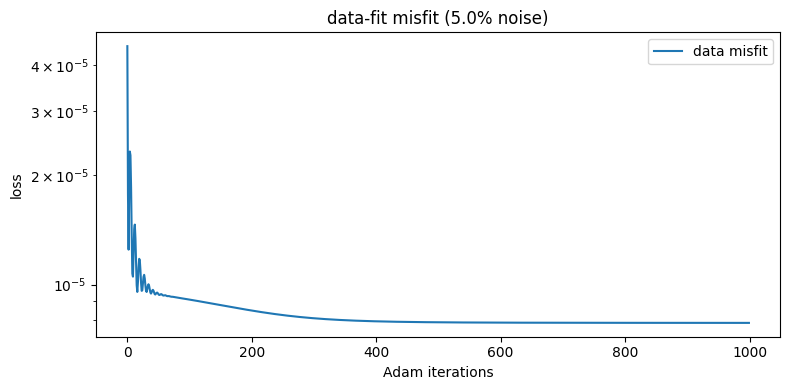

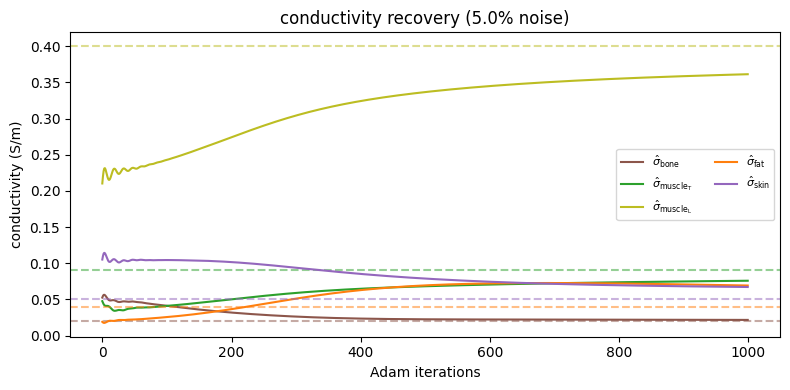

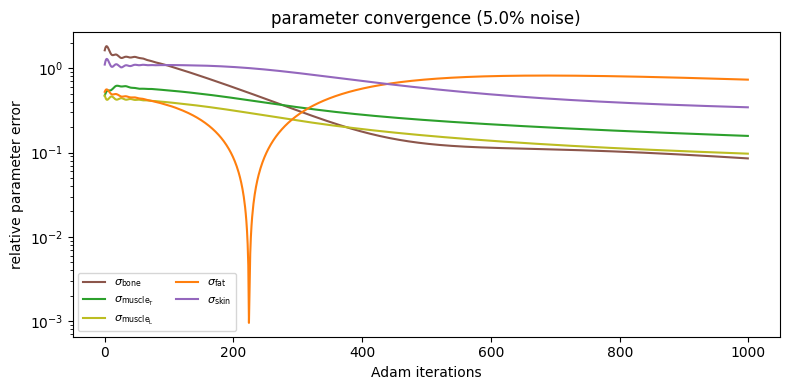

In [46]:
# convergence plots
print(f"Forward (data) resolution: {N}x{N}x{N}   |   Inverse resolution: {N_INV}x{N_INV}x{N_INV}")
print(f"Noise level: {NOISE_PERCENT:.1f}% Gaussian measurement noise")
print(f"surface electrodes: target coverage {ELECTRODE_COVERAGE:.2f}  ->  "
          f"realised {_n_elec / _n_surf:.3f} of the lateral surface")
print(f"{_n_elec} electrodes  ({_n_elec} of {_n_tot} volume nodes = "
          f"{100 * _n_elec / _n_tot:.2f}% of the field is observed)")

COLOURS = {"bone": "tab:brown", "muscle_T": "tab:green", "muscle_L": "tab:olive",
           "fat": "tab:orange", "skin": "tab:purple"}

# data misfit
fig1, ax1 = plt.subplots(figsize=(8, 4))
ax1.semilogy(loss_history, label="data misfit")
ax1.legend(); ax1.set_xlabel("Adam iterations"); ax1.set_ylabel("loss")
ax1.set_title(f"data-fit misfit ({NOISE_PERCENT:.1f}% noise)")
fig1.tight_layout()

# conductivity recovery: each layer's iterate against its true value
fig2, ax2 = plt.subplots(figsize=(8, 4))
for k in PARAM_NAMES:
    ax2.plot(sigma_history[k], color=COLOURS[k], label=fr"$\hat\sigma_{{\mathrm{{{k}}}}}$")
    ax2.axhline(sigma_true[k], color=COLOURS[k], ls="--", alpha=0.5)
ax2.legend(ncol=2, fontsize=8); ax2.set_xlabel("Adam iterations"); ax2.set_ylabel("conductivity (S/m)")
ax2.set_title(f"conductivity recovery ({NOISE_PERCENT:.1f}% noise)")
fig2.tight_layout()

# relative parameter error per layer, log scale
fig3, ax3 = plt.subplots(figsize=(8, 4))
for k in PARAM_NAMES:
    arr = np.array(sigma_history[k])
    ax3.semilogy(np.abs(arr - sigma_true[k]) / sigma_true[k], color=COLOURS[k],
                 label=fr"$\sigma_{{\mathrm{{{k}}}}}$")
ax3.legend(ncol=2, fontsize=8); ax3.set_xlabel("Adam iterations"); ax3.set_ylabel("relative parameter error")
ax3.set_title(f"parameter convergence ({NOISE_PERCENT:.1f}% noise)")
fig3.tight_layout()
plt.show();

In [ ]:
# I used Claude to implement the Gauss-Newton verification

In [45]:
# Gauss-Newton conditioning diagnostic: J^T J at the recovered point, where
# J = d phi_pred / d (log sigma_k) is the (M x 5) sensitivity of the predicted field to the
# five log-conductivities. Its eigenvalue spread says which parameters the data constrains.
# This is the natural entry point for Tikhonov regularisation later - sparse sampling at the skin surface.

_order = PARAM_NAMES
theta  = torch.stack([log_sigma[k].detach().clone() for k in _order]).requires_grad_(True)

def _residual_of_theta(theta_vec):
    lp = {k: theta_vec[i] for i, k in enumerate(_order)}
    sT_vec, sL_vec = assemble_sigma_vectors(lp)
    fh = layered_face_hierarchy(N_INV, sT_vec, sL_vec)
    return (forward(I_known, faces_by_n=fh) - potential_field_obs_t).reshape(-1)

# build J column by column: one Jacobian-vector product per parameter (reverse-mode, robust)
_cols = []
for i in range(len(_order)):
    v = torch.zeros(len(_order)); v[i] = 1.0
    _, jv = torch.autograd.functional.jvp(_residual_of_theta, theta, v, create_graph=False)
    _cols.append(jv.reshape(-1))
J   = torch.stack(_cols, dim=1)
JTJ = J.T @ J
evals = torch.linalg.eigvalsh(JTJ)

print("Gauss-Newton J^T J at the recovered conductivities")
print(f"  eigenvalues (asc): {[f'{e:.3e}' for e in evals.tolist()]}")
print(f"  condition number : {(evals[-1] / evals[0]).item():.3e}")
print("  per-parameter sensitivity (diag J^T J = ||d r / d log sigma_k||^2):")
for k, d in zip(_order, JTJ.diag().tolist()):
    print(f"    {k:9s} {d:.3e}")
print("\nLower sensitivity  ->  a parameter the data constrains weakly. Expect bone lowest:")
print("it is the smallest, deepest, lowest-contrast shell, so it moves the surface field least.")

Gauss-Newton J^T J at the recovered conductivities
  eigenvalues (asc): ['8.238e-05', '2.104e-04', '8.101e-04', '9.599e-03', '5.943e-02']
  condition number : 7.215e+02
  per-parameter sensitivity (diag J^T J = ||d r / d log sigma_k||^2):
    bone      1.270e-04
    muscle_T  1.008e-02
    muscle_L  5.719e-02
    fat       5.671e-04
    skin      2.175e-03

Lower sensitivity  ->  a parameter the data constrains weakly. Expect bone lowest:
it is the smallest, deepest, lowest-contrast shell, so it moves the surface field least.


In [ ]:
# I used Claude Code to implement these plotting cells to visualise the electric potentials phi

Forward (data) resolution: 65x65x65   |   Inverse resolution: 65x65x65
Noise level: 5.0% Gaussian measurement noise
Depth slice: z index 45 (z = 0.703)
surface electrodes: target coverage 0.50  ->  realised 1.000 of the lateral surface
16640 electrodes  (16640 of 274625 volume nodes = 6.06% of the field is observed)


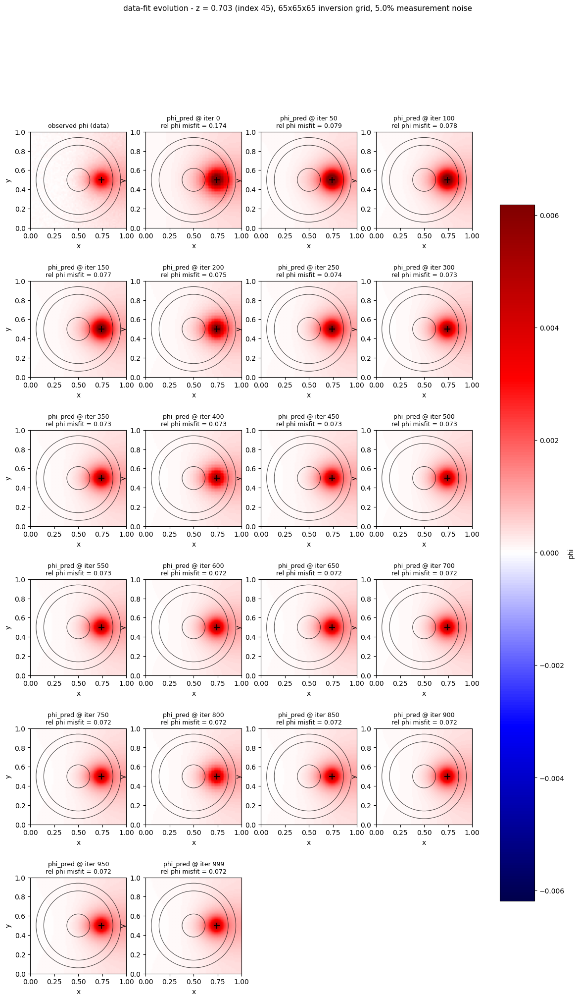

In [44]:
# observed field vs predicted field as the inversion proceeds, in tissue context

from matplotlib.patches import Circle

def _np(a):
    """torch tensor or numpy array -> numpy array."""
    return a.detach().cpu().numpy() if hasattr(a, "detach") else np.asarray(a)

def _draw_shells(ax):
    """Overlay the exact circular tissue interfaces r = R1, R2, R3 (the true circles,
    not the staircased grid boundary), so the field is read in its geometric context."""
    for R in (R1, R2, R3):
        ax.add_patch(Circle((X_C, Y_C), R, fill=False, ec="k", lw=0.8, alpha=0.7))

# depth slice (z index) to visualise; pick any 0 <= DEPTH_SLICE < N_INV
DEPTH_SLICE = 45
k   = DEPTH_SLICE
z_k = t_inv[k].item()

print(f"Forward (data) resolution: {N}x{N}x{N}   |   Inverse resolution: {N_INV}x{N_INV}x{N_INV}")
print(f"Noise level: {NOISE_PERCENT:.1f}% Gaussian measurement noise")
print(f"Depth slice: z index {k} (z = {z_k:.3f})")
print(f"surface electrodes: target coverage {ELECTRODE_COVERAGE:.2f}  ->  "
          f"realised {_n_elec / _n_surf:.3f} of the lateral surface")
print(f"{_n_elec} electrodes  ({_n_elec} of {_n_tot} volume nodes = "
          f"{100 * _n_elec / _n_tot:.2f}% of the field is observed)")

# Plot the same observed field the loss compared against - i.e. the zero-mean-projected
# tensor, not the raw sub-sample - so the observed panel and the (zero-mean) predicted
# snapshots share one gauge and the colour scale is consistent across all panels.
phi_obs_np = _np(potential_field_obs_t)
vmax = np.abs(phi_obs_np).max()          # shared symmetric colour scale over the whole volume

# assemble panels: observed first, then one per stored prediction snapshot
panels  = [("observed phi (data)", phi_obs_np, None)]
panels += [(f"phi_pred @ iter {it}", _np(phi_pred_np), rel)
           for (it, phi_pred_np, rel) in phi_snapshots]

ncols = min(4, len(panels))
nrows = int(np.ceil(len(panels) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.8 * nrows), squeeze=False)
axes_flat = axes.ravel()

im = None
for ax, (title, field, rel) in zip(axes_flat, panels):
    im = ax.imshow(field[:, :, k].T, origin="lower", extent=[0, 1, 0, 1],
                   cmap="seismic", vmin=-vmax, vmax=vmax)
    _draw_shells(ax)
    ax.plot([c_x], [c_y], marker="+", color="k", ms=9, mew=1.3)   # dipole fibre column (x, y)
    ax.set_title(title + ("" if rel is None else f"\nrel phi misfit = {rel:.3f}"), fontsize=9)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)

# hide any unused axes in the grid
for ax in axes_flat[len(panels):]:
    ax.axis("off")

fig.suptitle(f"data-fit evolution - z = {z_k:.3f} (index {k}), "
             f"{N_INV}x{N_INV}x{N_INV} inversion grid, {NOISE_PERCENT:.1f}% measurement noise",
             fontsize=11)
fig.colorbar(im, ax=axes, label="phi", shrink=0.8)
plt.show();

Forward (data) resolution: 65x65x65   |   Inverse resolution: 65x65x65
Noise level: 5.0% Gaussian measurement noise
Depth slice: z index 45 (z = 0.703)
surface electrodes: target coverage 0.50  ->  realised 1.000 of the lateral surface
16640 electrodes  (16640 of 274625 volume nodes = 6.06% of the field is observed)


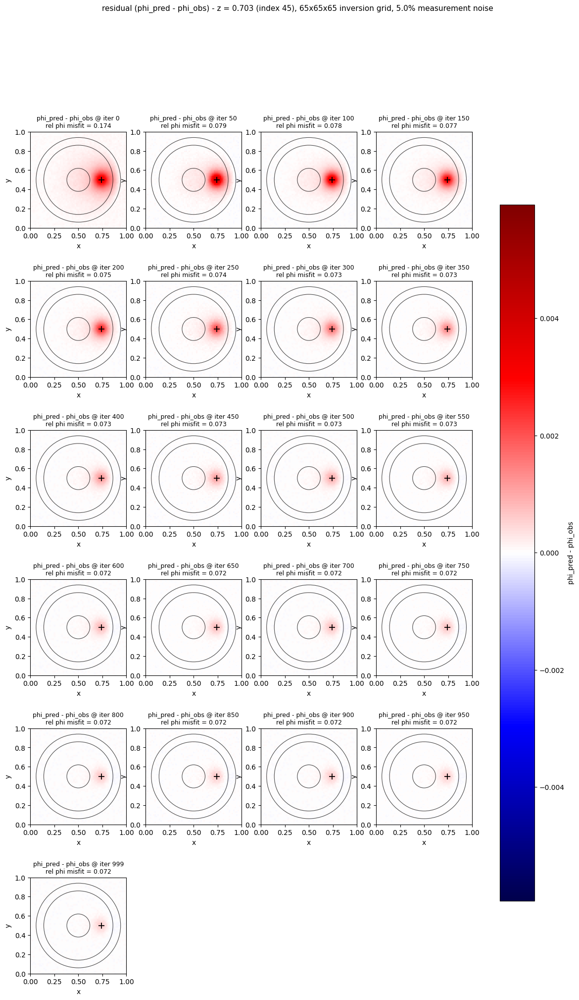

In [43]:
# the delta: residual maps (phi_pred - phi_obs) as the inversion proceeds, in tissue context

# depth slice (z index) to visualise; pick any 0 <= DEPTH_SLICE < N_INV
DEPTH_SLICE = 45
k   = DEPTH_SLICE
z_k = t_inv[k].item()

print(f"Forward (data) resolution: {N}x{N}x{N}   |   Inverse resolution: {N_INV}x{N_INV}x{N_INV}")
print(f"Noise level: {NOISE_PERCENT:.1f}% Gaussian measurement noise")
print(f"Depth slice: z index {k} (z = {z_k:.3f})")
print(f"surface electrodes: target coverage {ELECTRODE_COVERAGE:.2f}  ->  "
          f"realised {_n_elec / _n_surf:.3f} of the lateral surface")
print(f"{_n_elec} electrodes  ({_n_elec} of {_n_tot} volume nodes = "
          f"{100 * _n_elec / _n_tot:.2f}% of the field is observed)")

# residual against the SAME observed field the loss used (zero-mean gauge), matching the
# previous cell - so each map is exactly phi_pred minus the loss target, with no gauge offset.
phi_obs_np = _np(potential_field_obs_t)

# per-snapshot residual maps, and a shared symmetric colour scale over all of them
residuals = [(it, _np(phi_pred_np) - phi_obs_np, rel_misfit)
             for (it, phi_pred_np, rel_misfit) in phi_snapshots]
vmax = max(np.abs(d).max() for (_, d, _) in residuals)   # shared scale over the whole volume

ncols = min(4, len(residuals))
nrows = int(np.ceil(len(residuals) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.8 * nrows), squeeze=False)
axes_flat = axes.ravel()

im = None
for ax, (it, d, rel_misfit) in zip(axes_flat, residuals):
    im = ax.imshow(d[:, :, k].T, origin="lower", extent=[0, 1, 0, 1],
                   cmap="seismic", vmin=-vmax, vmax=vmax)
    _draw_shells(ax)                                          # exact tissue interfaces
    ax.plot([c_x], [c_y], marker="+", color="k", ms=9, mew=1.3)   # dipole fibre column (x, y)
    ax.set_title(f"phi_pred - phi_obs @ iter {it}\nrel phi misfit = {rel_misfit:.3f}", fontsize=9)
    ax.set_xlabel("x"); ax.set_ylabel("y")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)

# hide any unused axes in the grid
for ax in axes_flat[len(residuals):]:
    ax.axis("off")

fig.suptitle(f"residual (phi_pred - phi_obs) - z = {z_k:.3f} (index {k}), "
             f"{N_INV}x{N_INV}x{N_INV} inversion grid, {NOISE_PERCENT:.1f}% measurement noise",
             fontsize=11)
fig.colorbar(im, ax=axes, label="phi_pred - phi_obs", shrink=0.8)
plt.show();

In [ ]:
# fading is the convergence